# News Articles Sentiment Scores

This notebook contains the Natural Language Processing for both the yahoo news articles and the content of the news articles found on the web pages of the companies.

NOTE: we didn't do sentiment analysis with textblob since it is outdated

In [ ]:
# Import dependencies
import findspark, pyspark
import os
import pandas as pd
import numpy as np
import re
import string
import spacy
from functools import reduce
from pyspark.sql import DataFrame
import umap
import umap.plot
from mpl_toolkits.mplot3d import Axes3D
import random

import matplotlib.pyplot as plt
import seaborn as sns

import pyspark.sql.functions as F
from pyspark.sql.types import ArrayType, DoubleType, NumericType, StringType, StructType, StructField, FloatType
from pyspark.ml.feature import Word2Vec, StandardScaler, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array
from pyspark.ml.linalg import Vectors, VectorUDT

from pyspark.ml import Pipeline

from textblob import TextBlob

from string import punctuation
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from pyspark.sql import SparkSession, Window
from pyspark import SparkConf
from pyspark.sql.functions import col, rand, when, avg, count, round
import psutil, os, time, pandas as pd, matplotlib.pyplot as plt

from sklearn.manifold import TSNE 
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity

# Initialize findspark to locate Spark installation
#findspark.init('/Users/douwepauwels/sources/spark')

/opt/anaconda3/lib/python3.12/site-packages/numba/np/ufunc/dufunc.py:343: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/opt/anaconda3/lib/python3.12/site-packages/numba/np/ufunc/dufunc.py:343: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/opt/anaconda3/lib/python3.12/site-packages/numba/np/ufunc/dufunc.py:343: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)


In [2]:
# Create Spark1 session: we use the following configurations:

# - master("local[*]"): Run Spark locally with as many worker threads as logical cores on your machine.
# - config("spark.driver.memory", "1g"): Allocate 1 GB of memory to the Spark driver.
# - config("spark.executor.memory", "2g"): Allocate 2 GB of memory to each Spark executor.
# - appName("IntroToSpark"): Name the Spark application "IntroToSpark".

spark = (SparkSession.builder
    .master("local[*]")
    .appName("IntroToSpark1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.host", "127.0.0.1")
    # Optional: let Spark pick a free UI port instead of hardcoding 4040
    .config("spark.ui.enabled", "true")
    .config("spark.ui.port", "0")
    .config("spark.driver.memory", "2g")
    .getOrCreate())

sc1 = spark.sparkContext  # To access SparkContext if needed
spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/12/15 16:37:19 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Data Preprocessing

In [5]:
tickers_df = pd.read_csv('../Data/tickers.csv')
tickers_df

,tickers,Company Name
0,ARG.TO,Amerigo Resources Ltd
1,AYA.TO,Aya Gold & Silver Inc
2,CG.TO,Centerra Gold Inc
3,CGC.V,Canadian Gold Corp
4,CKG.V,Chesapeake Gold Corp
5,DMX.V,District Metals Corp
6,DV.V,Dolly Varden Silver Corp
7,EDG.V,Endurance Gold Corp
8,ELO.TO,Eloro Resources Ltd
9,EQX,Equinox Gold Corp


These are all the functions needed for preprocessing the data + A List of all the content preprocessing functions

In [5]:
# -----------------------
# REMOVE TEXT FUNCTIONS
# -----------------------

# define punctuation and stopwords
PUNCTUATION = [char for char in punctuation if char not in ["!", "@", "#", "%", "(", ")", "( )"]] # ADD more if needed
STOPWORDS = stopwords.words("english")
CONTEXT_WORDS = ['gold', 'silver', 'copper']

# define function to remove punctuation
def remove_punct(text):
    # remove punctuation
    text = "".join([char for char in text if char not in PUNCTUATION])
    return(text)

# define function to remove stopwords
def remove_stopwords(text):
    text = " ".join([word for word in text.split(" ") if word not in STOPWORDS])
    return(text)

# define function to remove context words
def remove_context_words(text):
    text = " ".join([word for word in text.split(" ") if word not in CONTEXT_WORDS])
    return(text)


# define function to remove urls
def remove_urls(text):
    url_pattern = r'http\S+|www\.\S+'
    return re.sub(url_pattern, '', text)

# define function to remove numbers 
def remove_numbers(text):
    pattern = r'\b\d+(\.\d+)?([kKmMbB])?\b|\$\d+(\.\d+)?'
    return re.sub(pattern, '', text)

# define function to remove stock tickers 
def remove_tickers(text):
    # tickers like AEM.TO, AAA.V, XYZ.CD
    ticker_pattern = r'\b[A-Z]{2,5}\.[A-Z]{1,3}\b'
    # tickers like AAPL, TSLA
    plain_ticker_pattern = r'\b[A-Z]{2,5}\b'
    # cashtags like $AAPL
    cashtag_pattern = r'\$[A-Za-z]{2,5}'

    text = re.sub(ticker_pattern, '', text)
    text = re.sub(cashtag_pattern, '', text)
    text = re.sub(plain_ticker_pattern, '', text)
    return text

# define function to remove unnecassary whitespaces
def clean_whitespace(text):
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# define function to lemmatize text
nlp = spacy.load("en_core_web_lg")

def spacy_lemmatize(text):
    doc = nlp(text)
    return " ".join([token.lemma_ for token in doc])

# define function to remove everything between parantheses
def remove_parentheses(text):
    if text is None:
        return None
    # remove nested parentheses safely by repeating until stable
    prev = None
    while prev != text:
        prev = text
        text = re.sub(r'\([^()]*\)', '', text)
    return text

#... 

# -----------------------
# Removing part of the text: general company info after each article, licence info, etc.
# -----------------------
# INIT DICTIONARY WITH REGEXES
regex_dict = {
    'ARG.TO': [
        r'About Amerigo.*',  # remove "About Amerigo" and everything after (same line unless DOTALL)
        r'^.*?\([“"]Amerigo[”"]\s+or\s+the\s+[“"]Company[”"]\)',  # remove everything before + that parenthetical (+ optional comma)
        r'Amerigo'
    ],
    'AYA.TO': [
        r'^.*?\([“"]Aya[”"]\s+or\s+the\s+[“"]Corporation[”"]\)',
        r'^.*?\(\s*«\s*Aya\s*»\s+ou\s+la\s+«\s*Société\s*»\s*\)', 
        r'(?s)À propos d’Aya Or & Argent Inc\..*', 
        r'(?s)About Aya Gold & Silver Inc\..*',
        r'Aya'
    ],
    'CG.TO': [
        r'^.*?\([“"]Centerra[”"]\s+or\s+the\s+[“"]Company[”"]\)',
        r'About Centerra Gold.*',
        r'Conference Call.*',
        r'Centerra'
    ],
    'CGC.V': [
        r'^.*?\([“"]Canadian Gold[”"]\s+or\s+the\s+[“"]Company[”"]\)',
        r'^.*?\([“"]Canadian Gold[”"]\)',
        r'About Canadian Gold.*',
        r'Canadian'
    ],
    'CKG.V': [
        r'^.*?\([“"]Chesapeake[”"]\s+or\s+the\s+[“"]Company[”"]\)',
        r'For Further Information:.*',
        r'Chesapeake'
    ],
    'DMX.V': [
        r'^.*?\([“"]District[”"]\s+or\s+the\s+[“"]Company[”"]\)',
        r'About District Metals Corp.*',
        r'Technical Information.*',
        r'References:.*'
        r'District'
    ],
    'DV.V': [
        r'^.*?\(the+\s+[“"]Company[”"]\s+or\s+[“"]Dolly Varden[”"]\)',
        r'About Dolly Varden Silver Corporation.*', 
        r'Dolly Varden'
    ],  
    'EDG.V': [
        r'^.*?\(the+\s+[“"]Company[”"]\)',
        r'FOR FURTHER INFORMATION, PLEASE CONTACT.*', 
        r'Endurance Gold', 
        r'ENDURANCE GOLD CORPORATION'
    ],
    'ELO.TO': [
        r'^.*?\([“"]Eloro[”"],\s+or\s+the\s+[“"]Company[”"]\)',
        r'^.*?\([“"]Eloro[”"]\s+or\s+the\s+[“"]Company[”"]\)',
        r'About Eloro Resources Ltd.*',
        r'Eloro'
    ],
    'EQX': [
        r'^.*?\([“"]Equinox Gold[”"]\s+or\s+the\s+[“"]Company[”"]\)',
        r'About Equinox Gold.*',
        r'CONFERENCE CALL AND WEBCAST.*', 
        r'Equinox Gold Contact.*',
        r'Equinox'
    ],
    'ESK.V': [
        r'^.*?\([“"]Eskay[”"]\s+or\s+the\s+[“"]Company[”"]\)',
        r'About Eskay Mining Corp:.*', 
        r'For further information, please contact:.*',
        r'Eskay'
    ],
    'FAS.V': [
        r'^.*?\(the+\s+[“"]Company[”"]\s+or\s+[“"]First Andes[”"]\)',
        r'^.*?\([“"]First Andes[”"],\s+or\s+the\s+[“"]Company[”"]\)',
        r'About First Andes Silver Ltd.*', 
        r"First Andes"
    ],
    'FDY.TO': [
        r'(?s)^.*?\(\s*"Faraday"\s+or\s+the\s+"Company"\s*\)',
        r'^.*?\([“"]Faraday[”"],\s+or\s+the\s+[“"]Company[”"]\)',
        r'About Faraday Copper.*',
        r'Faraday'
    ],  
    'FINX.V': [
        r'^.*?\([“"]FinEx[”"]\s+or\s+the\s+[“"]Company[”"]\)',
        r'About FinEx Metals Ltd.*'
    ],
    'FNM.V': [
        r'^.*?\(the+\s+[“"]Company[”"]\s+or\s+[“"]FNM[”"]\)',
        r'^.*?\(the+\s+[“"]Company[”"]\s+or\s+[“"]First Nordic[”"]\)',
        r'^.*?\([“"]FNM[”"],\s+or\s+the\s+[“"]Company[”"]\)',
        r'^.*?\([“"]Gold Line[”"]\)',
        r'For further information, please contact:.*', 
        r'About Gold Line Resources Ltd.*', 
        r'About Barsele Minerals Corp.*',
        r'ABOUT FIRST NORDIC METALS.*',
        r"First Nordic"
    ],
    'FOM.TO': [
        r'^.*?\([“"]Foran[”"],\s+or\s+the\s+[“"]Company[”"]\)',
        r'FOR ADDITIONAL INFORMATION & MEDIA ENQUIRIES:.*'
        r'Foran'
    ],
    'FURY.TO': [
        r'^.*?\([“"]Fury[”"],\s+or\s+the\s+[“"]Company[”"]\)',
        r'About Fury Gold Mines Limited.*'
        r'Fury'
    ],
    'FVL.TO': [
        r'\(\s*TSX:\s*FVL\s*,\s*OTCQX:\s*FGOVF\s*\)',
        r'About Freegold Ventures Limited.*',
        r'Freegold'
    ],
    'FWZ.V': [
        r'\(\s*TSXV:\s*FWZ\s*;\s*OTCQX:\s*FWEDF\s*\)',
        r'About Fireweed.*', 
        r'Qualified Person Statement.*',
        r'Fireweed'
    ]
}

# Function
def remove_redundant_text_udf_factory(ticker):
    def _remove(text):
        regexes = regex_dict[ticker]
        for regex in regexes:
            text = re.sub(regex, '', text, flags=re.DOTALL)
        return text
    return F.udf(_remove, StringType())


# -----------------------
# DON'T forget to register them as a udf 
# -----------------------
remove_punct_udf = F.udf(remove_punct, StringType())
remove_stopwords_udf = F.udf(remove_stopwords, StringType())
remove_context_words_udf = F.udf(remove_context_words, StringType())
remove_urls_udf = F.udf(remove_urls, StringType())
remove_numbers_udf = F.udf(remove_numbers, StringType())
remove_tickers_udf = F.udf(remove_tickers, StringType())
clean_whitespace_udf = F.udf(clean_whitespace, StringType())
spacy_lemmatize_udf = F.udf(spacy_lemmatize, StringType())
remove_parentheses_udf = F.udf(remove_parentheses, StringType())

In [6]:
# -----------------------
# Open the data and store in a spark dataframe
# -----------------------

def open_data_ticker(data_dir, type_data, ticker):
    '''
    data_dir: directory name to the textual data 
    type_data: Yahoo_articles or Company_news_page_data
    ticker: ticker
    '''

    # -------------
    # Open the correct directory
    # -------------
    if type_data == 'Yahoo_articles':
        directory = f'{data_dir}{type_data}/yahoo_articles_{ticker}.jsonl'

        # -------------
        # Read data + Rename columns
        # -------------

        json_df = spark.read.option("multiLine", 'false') \
                        .json(directory) \
                        .withColumnRenamed('published', 'date') \
                        .withColumnRenamed('text', 'content') 
        
    else: 
        directory = f'{data_dir}{type_data}/{ticker}_news.json'


        # -------------
        # Read data + add ticker column
        # -------------

        json_df = spark.read.option("multiLine", 'true') \
                        .json(directory) \
                        .withColumn('ticker', F.lit(ticker)) \
                        .select(['date', 'content', 'ticker', 'title', 'url'])
        

    # -------------
    # Remove rows for which content is empty
    # -------------
    json_df = json_df.filter(F.col("content") != "")


    # RETURN DF
    return json_df

# -----------------------
# Cleaning function for a whole dataframe 
# -----------------------
def clean_df(df):
    cleaned_df = df \
                        .withColumn("content", remove_urls_udf("content")) \
                        .withColumn("title", remove_urls_udf("title")) \
                        .withColumn("content", remove_numbers_udf("content")) \
                        .withColumn("title", remove_numbers_udf("title")) \
                        .withColumn("content", remove_tickers_udf("content")) \
                        .withColumn("title", remove_tickers_udf("title")) \
                        .withColumn("content", F.lower("content")) \
                        .withColumn("title", F.lower("title")) \
                        .withColumn("content", remove_stopwords_udf("content")) \
                        .withColumn("title", remove_stopwords_udf("title")) \
                        .withColumn("content", remove_context_words_udf("content")) \
                        .withColumn("title", remove_context_words_udf("title")) \
                        .withColumn("content", remove_punct_udf("content")) \
                        .withColumn("title", remove_punct_udf("title")) \
                        .withColumn("content", remove_parentheses_udf("content")) \
                        .withColumn("title", remove_parentheses_udf("title")) \
                        .withColumn("content", F.regexp_replace("content", "\n", " ")) \
                        .withColumn("title", F.regexp_replace("title", "\n", " ")) \
                        .withColumn("content", clean_whitespace_udf("content")) \
                        .withColumn("title", clean_whitespace_udf("title")) \
                        .withColumn("content_lemma", spacy_lemmatize_udf("content")) \
                        .withColumn("title_lemma", spacy_lemmatize_udf("title")) \
                        .withColumn("title_tokenized", F.split("title", " ")) \
                        .withColumn("content_tokenized", F.split("content", " ")) \
                        .withColumn("num_words_title", F.size("title_tokenized")) \
                        .withColumn("num_words_content", F.size("content_tokenized"))
    
    return cleaned_df

# -----------------------
# Preprocessing fucntion for all the yahoo news articles
# -----------------------

def preprocessing_yahoo(df, ticker): 
    '''
    df: dataframe with the articles of one company
    '''

    # -------------
    # Format date to datetime 
    # -------------
    df = df.withColumn("date", F.to_date("date"))

    # -------------
    # Clean content of redundant text
    # -------------
    remove_redundant_text_udf = remove_redundant_text_udf_factory(ticker)
    df = df.withColumn(
        'content',
        remove_redundant_text_udf(F.col('content'))
    )
    
    # -------------
    # Clean df
    # -------------
    cleaned_df = clean_df(df)

    return cleaned_df

# -----------------------
# Preprocessing function for all the articles on the company websites
# -----------------------
def preprocessing_news_websites(df, date_dict, ticker):
    '''
    df: dataframe with the articles of one company
    date_dict: dictionary with as keys the tickers of a company and as value the date format used in the articles
    ticker: current ticker of the company
    '''

    # -------------
    # Format date to datetime 
    # -------------
    format = date_dict[ticker]

    df = df.withColumn(
        "date_ts",
        F.expr(f"try_to_timestamp(date, '{format}')")
    )

    df = df.withColumn("date", F.to_date("date_ts")).drop("date_ts")

    # -------------
    # Clean content of redundant text
    # -------------
    remove_redundant_text_udf = remove_redundant_text_udf_factory(ticker)
    df = df.withColumn(
        'content',
        remove_redundant_text_udf(F.col('content'))
    )

    # -------------
    # Clean df
    # -------------
    cleaned_df = clean_df(df)

    return cleaned_df

# -----------------------
# Main
# -----------------------
def main_preProcess(type_data):

    # -----------------------   
    # Load and preprocess biweekly data
    # -----------------------
    biweekly_data = spark.read.parquet("../Cleaned_data/biweekly_basetable.parquet") \
                              .select("period_start", "period_end", "biweekly_period", "financing_next_period", "biweekly_index") \
                              .withColumnRenamed("financing_next_period", "next_announcement")

    # -----------------------   
    # INIT 
    # -----------------------
    data_dir = '../Data/Textual_data/'
    preprocessed_data_full = []
    date_dict = {
        'ARG.TO' : 'MM.dd.yyyy', 
        'AYA.TO' : 'dd MMM yyyy', 
        'CG.TO' : 'MMMM dd, yyyy', 
        'CGC.V' : 'MMMM dd, yyyy', 
        'CKG.V' : 'MMMM dd, yyyy', 
        'DMX.V' : 'MMMM dd, yyyy', 
        'DV.V' : 'MMMM dd, yyyy', 
        'EDG.V' : 'MMM dd, yyyy', 
        'ELO.TO' : 'dd\nMMMM\nyyyy', 
        'EQX' : 'MMMM dd, yyyy', 
        'ESK.V' : 'MMMM dd, yyyy', 
        'FAS.V' : 'MMMM dd, yyyy', 
        'FDY.TO' : 'MMM dd, yyyy',  
        'FINX.V' : 'MMMM dd, yyyy', 
        'FNM.V' : 'MMMM dd, yyyy', 
        'FOM.TO' : 'MMMM dd, yyyy', 
        'FURY.TO' : 'MMMM dd, yyyy', 
        'FVL.TO' : 'MMM dd, yyyy',
        'FWZ.V' : 'MMMM dd, yyyy', 
    }

    # -----------------------   
    # Main loop 
    # -----------------------   

    for ticker in tickers_df['tickers'].to_list():

        # FILTER BIWEEKLY DATA ON TICKER
        biweekly_data_filtered = biweekly_data.filter(F.col("ticker") == ticker)

        # LOAD DATA 
        loaded_df = open_data_ticker(
            data_dir=data_dir, 
            type_data=type_data, 
            ticker=ticker
        )

        # PREPROCESS DATA
        if type_data == 'Yahoo_articles':
            preprocessed_data = preprocessing_yahoo(
                df = loaded_df,
                ticker=ticker
            )

        else : 
            preprocessed_data = preprocessing_news_websites(
                df = loaded_df, 
                date_dict = date_dict, 
                ticker = ticker 
            )

        # MERGE BIWEEKLY DATA
        preprocessed_data_with_period = preprocessed_data.join(
            biweekly_data_filtered.select("period_start", "period_end", "biweekly_period", "next_announcement", "biweekly_index"),
            (F.col("date") >= F.col("period_start")) & (F.col("date") <= F.col("period_end")),
            how="right"  
        ).cache()

        # APPEND 
        preprocessed_data_full.append(preprocessed_data_with_period)


    return preprocessed_data_full

In [7]:
if __name__ == "__main__":
    dfs_yahoo = main_preProcess('Yahoo_articles')
    dfs_company_websites = main_preProcess('Company_news_page_data')

    dfs = []

    for df in range(len(dfs_yahoo)):

        df_union = dfs_yahoo[df].unionAll(dfs_company_websites[df])

        dfs.append(df_union)

    print(len(dfs))

19


In [8]:
# EXAMPLE AYA.TO
dfs[0].select('date', 'content').collect()

[Row(date=None, content=None),
 Row(date=None, content=None),
 Row(date=datetime.date(2025, 5, 15), content='even though resources ltds () recent earnings release robust market didnt seem notice analysis suggests investors might missing promising details our free stock report includes warning signs investors aware investing resources read free now one key financial ratio used measure well company converts profit free cash flow () accrual ratio plain english ratio subtracts net profit divides number companys average operating assets period ratio tells us much companys profit backed free cashflow that means negative accrual ratio good thing shows company bringing free cash flow profit would suggest intended imply worry positive accrual ratio worth noting accrual ratio rather high quote paper lewellen resutek firms higher accruals tend less profitable future for year march resources accrual ratio indicates free cash flow quite significantly exceeded statutory profit fact free cash flow us

## Sentiment analysis using TextBlob

functions to retrieve the sentiment scores

In [9]:
# -----------------------
# POLARITY AND SUBJECTIVITY
# -----------------------
def get_polarity(row):
    textBlob_review = TextBlob(row)
    return textBlob_review.sentiment[0]

def get_subjectivity(row):
    textBlob_review = TextBlob(row)
    return textBlob_review.sentiment[1]

# register functions as udf
get_polarity_udf = F.udf(get_polarity, DoubleType())
get_subjectivity_udf = F.udf(get_subjectivity, DoubleType())

def main_textBlob(list_dfs):

    dfs_with_sentiment = []

    for df in list_dfs:
        df_with_sentiment = df.withColumn("polarity_title", get_polarity_udf(F.col("title_lemma"))) \
                              .withColumn("polarity_content", get_polarity_udf(F.col("content_lemma"))) \
                              .withColumn("subjectivity_title", get_subjectivity_udf(F.col("title_lemma"))) \
                              .withColumn("subjectivity_content", get_subjectivity_udf(F.col("content_lemma"))) \
                              .filter("num_words_title > 0 OR num_words_content > 0") \
                              .drop("url") \
                              .cache()
                            

        dfs_with_sentiment.append(df_with_sentiment)
        
    return dfs_with_sentiment

In [10]:
if __name__ == "__main__":

    dfs = main_textBlob(dfs)

In [11]:
# EXAMPLE: AYA.TO
dfs[1].show()

+----------+--------------------+------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------+--------------------+--------------------+-------------------+--------------------+
|      date|             content|ticker|               title|       content_lemma|         title_lemma|     title_tokenized|   content_tokenized|num_words_title|num_words_content|period_start|period_end|biweekly_period|next_announcement|biweekly_index|      polarity_title|    polarity_content| subjectivity_title|subjectivity_content|
+----------+--------------------+------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------+--------------------+--------------------+-------------------+--------------

## Vector Embeddings using FinBERT

In [12]:
#To install torch with cuda support, follow instructions at https://pytorch.org/get-started/locally/. This will ensure that the model runs on GPU if available.
import torch

from pyspark.ml.functions import array_to_vector
from transformers import AutoTokenizer, AutoModel

Function list for embedding the text

In [13]:
# -----------------------
# INIT MODEL AND TOKENIZER
# -----------------------
MODEL_NAME = "ProsusAI/finbert"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

_tokenizer = None
_model = None

def get_model_and_tokenizer():
    global _tokenizer, _model
    if _tokenizer is None or _model is None:
        _tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
        _model = AutoModel.from_pretrained(MODEL_NAME)
        _model.to(device)
        _model.eval()
    return _tokenizer, _model


# -----------------------
# EMBEDDING TEXT
# -----------------------
def get_embeddings(text):
    if text is None or text == "":
        return None
    
    tokenizer, model = get_model_and_tokenizer()
    
    # Tokenize the input text
    inputs = tokenizer(text, 
                     padding=True, 
                     truncation=True, 
                     max_length=512,
                     return_tensors="pt")
    
    # Move inputs to device
    inputs = {key: val.to(device) for key, val in inputs.items()}
    
    # Generate embeddings without gradient computation
    with torch.no_grad():
        outputs = model(**inputs)

    # Mean pooling - take attention mask into account for correct averaging so we don't include padding tokens
    attention_mask = inputs['attention_mask']
    token_embeddings = outputs.last_hidden_state
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    embeddings = torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)
    
    # Convert to numpy and then to list
    embedding_list = embeddings.cpu().numpy()[0].tolist()
    
    return embedding_list

# Register the function as a UDF
get_embeddings_udf = F.udf(get_embeddings, ArrayType(DoubleType()))

# -----------------------
# MAIN 
# -----------------------
def main_finBERT(list_dfs):

    dfs_with_embeddings = [] 

    for df in list_dfs:

        # APPLY EMBEDDING
        df_with_embeddings = df.withColumn(
            "finbert_embeddings", 
            get_embeddings_udf(F.col("content"))
        )

        # VECTOR ARRAY
        df_with_embeddings = df_with_embeddings.filter(F.col("finbert_embeddings").isNotNull()) \
                                               .withColumn("finbert_embeddings", array_to_vector(F.col("finbert_embeddings"))) \
                                               .cache()
    
        # APPEND 
        dfs_with_embeddings.append(df_with_embeddings)

    # RETURN 
    return dfs_with_embeddings

In [14]:
if __name__ == "__main__":

    dfs = main_finBERT(dfs)

In [15]:
# EXAMPLE: AYA.TO
dfs[0].show()

+----------+--------------------+------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------+--------------+--------------------+------------------+--------------------+--------------------+
|      date|             content|ticker|               title|       content_lemma|         title_lemma|     title_tokenized|   content_tokenized|num_words_title|num_words_content|period_start|period_end|biweekly_period|next_announcement|biweekly_index|polarity_title|    polarity_content|subjectivity_title|subjectivity_content|  finbert_embeddings|
+----------+--------------------+------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------+--------------+--------------------+------------

## Sentiment Analysis uing Ollama

In [16]:
# ----------------------------------------------------
# INIT MODEL NAME
# ----------------------------------------------------
import ollama
MODEL_NAME = 'gemma3:4b'

# ----------------------------------------------------
# OLLAMA 
# ----------------------------------------------------
# Function to get sentiment using ollama
def get_ollama_sentiment(text):
    try:
        prompt = f"""
You are a financial sentiment classifier.

The input text can be in ANY language (English, Dutch, French, German, etc.).
If it is not in English, first translate it mentally to English.
Then evaluate its sentiment for an investor.

Output exactly ONE real number between -1 and 1
(-1 = very negative, 0 = neutral, 1 = very positive).
Use a dot as decimal separator. Do NOT output anything else.

Text:
{text}
"""
        
        response = ollama.chat(model=MODEL_NAME, 
                               messages=[
                                {
                                    'role': 'user',
                                    'content': prompt
                                }
                            ])
        score = response['message']['content'].strip()
        score = score.replace(",", ".")  # support comma decimals

        # Extract first float-like number from the response
        match = re.search(r"-?\d+(?:\.\d+)?", score)
        if not match:
            # model didn't output a number → neutral
            return "0"

        val = float(match.group())

        # Clip to [-1, 1] just in case
        if val < -1.0:
            val = 0
        elif val > 1.0:
            val = 0

        return str(val)

    except Exception as e:
        return 0
    
# Register udf
get_ollama_sentiment_udf = F.udf(get_ollama_sentiment, StringType())


# ----------------------------------------------------
# MAIN: add Ollama sentiment to each article
# ----------------------------------------------------
def main_ollama(list_dfs):
    """
    Takes a list of Spark DataFrames
    
    'ollama_sentiment': string with the numeric sentiment between -1 and 1.
    """
    dfs_with_sentiment = []

    for df in list_dfs:
        df_with_sentiment = df.withColumn(
            "ollama_sentiment",
            get_ollama_sentiment_udf(F.col("content"))
        ).cache()
        dfs_with_sentiment.append(df_with_sentiment)

    return dfs_with_sentiment

In [17]:
if __name__ == "__main__":

    dfs = main_ollama(dfs)

In [18]:
# EXAMPLE AYA.TO
dfs[1].show(200)

+----------+--------------------+------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------+--------------------+--------------------+-------------------+--------------------+--------------------+----------------+
|      date|             content|ticker|               title|       content_lemma|         title_lemma|     title_tokenized|   content_tokenized|num_words_title|num_words_content|period_start|period_end|biweekly_period|next_announcement|biweekly_index|      polarity_title|    polarity_content| subjectivity_title|subjectivity_content|  finbert_embeddings|ollama_sentiment|
+----------+--------------------+------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------+

# Case One: Financing pressure index (FPI)

Quantify how the semantic content of a company’s news flow evolves in a way that can signal increasing likelihood of a financing announcement in the next 2 weeks.

This index becomes:

* a predictive feature for your financing-announcement model
* a managerial signal for early warning
* a research finding showing how communication patterns change



### Approach A: Embedding drift from the baseline 
**Steps:**

1. Step One: Cluster all news embeddings (KMeans, spectral clustering, HDBSCAN, etc.), before clustering the data, make use of dimensionality reduction techniques
    * t-SNE 
    * or UMAP
2. Step Two: Identify the baseline communication cluster
3. Step Three: Compute the centroid of this cluster
4. Step Four: For each boiweekly aggregated embedding: compute the cosine distance to this baseline centroid 
5. Step Five: You just computed the Financing pressure index 

(Step Six: Scale this feature)

In [19]:
# -------------------------------------------------------
# Function that takes the average over a group of vectors
# -------------------------------------------------------
def mean_array(arrs):
    """
    arrs: list of embeddings, each embedding is a list/array of floats.
    Returns element-wise mean embedding as a Python list of floats.
    """
    if arrs is None or len(arrs) == 0:
        return None

    n = len(arrs)
    dim = len(arrs[0])

    sums = [0.0] * dim
    count = 0

    for a in arrs:
        if a is None:
            continue
        count += 1
        for i, v in enumerate(a):
            sums[i] += float(v)

    if count == 0:
        return None

    return [s / count for s in sums]

mean_array_udf = F.udf(mean_array, ArrayType(DoubleType()))

# Optional: if you want the result back as a Spark Vector
to_vec_udf = F.udf(
    lambda arr: Vectors.dense(arr) if arr is not None else None,
    VectorUDT()
)

# -------------------------------------------------------
# Function that maps the reduced embeddings in 3D
# -------------------------------------------------------

def draw_umap(u, n_components=3, title='UMAP, n_components: 3'):
    random.seed(1)
    fig = plt.figure()
    if n_components == 1:
        ax = fig.add_subplot(111)
        ax.scatter(u[:,0], range(len(u)))
    if n_components == 2:
        ax = fig.add_subplot(111)
        ax.scatter(u[:,0], u[:,1])
    if n_components == 3:
        ax = fig.add_subplot(111, projection='3d')
        ax.scatter(u[:,0], u[:,1], u[:,2], s=100)
    plt.title(title, fontsize=18)

def dim_reduction(embeddings, dimensionality_red: str):
    
    if dimensionality_red == 'tsne':
        # -----------------------------------
        # Dimensionality reduction: t-SNE
        # -----------------------------------
        # INIT t-SNE
        random.seed(1)
        tsne = TSNE(
            n_components=3, 
            perplexity=5, 
            max_iter=250
        )

        # FIT & TRANSFORM
        reduced_embeddings = tsne.fit_transform(embeddings)

    else: 
        # -----------------------------------
        # Dimensionality reduction: UMAP
        # -----------------------------------
        # INIT UMAP
        random.seed(1)
        reducer = umap.UMAP(
            n_neighbors=4, # Default is 15 --> Use lower value for more local
            min_dist=0.2, # Default 0.1
            n_components=3, # Default
            metric='cosine'
        )

        # FIT & TRANSFORM
        reduced_embeddings = reducer.fit_transform(embeddings)
        draw_umap(u=reduced_embeddings, n_components=3)

    return reduced_embeddings

def clustering(embeddings, periods, announcements):
    # INIT
    random.seed(1)
    dbscan = DBSCAN(eps=2, min_samples=3)
    labels = dbscan.fit_predict(embeddings)

    df = pd.DataFrame({
        'biweekly_period': [str(p) for p in periods],
        'label' : [lab for lab in labels], 
        'finbert_arr' : [comp for comp in dbscan.components_], 
        'next_announcement': [a for a in announcements]
    })

    return df

def compute_centroid(df):
    max_label = df.groupby(by='label') \
                  .count() \
                  .reset_index() \
                  .sort_values('finbert_arr', ascending=False) \
                  .reset_index() \
                  .head(1)['label'][0]
    max_label_embedding = mean_array(list(df[df['label'] == max_label]['finbert_arr']))

    return max_label, max_label_embedding

def compute_PFI(df, dimensionality_red: str): 
    # -----------------------------------
    # INIT  
    # -----------------------------------
    df = df.withColumn("finbert_arr", vector_to_array("finbert_embeddings"))
    rows = df.select(["biweekly_period", "next_announcement", "finbert_arr"])
    rows = rows.collect()

    announcements = np.array([row['next_announcement'] for row in rows])
    periods = np.array([row["biweekly_period"] for row in rows])
    embeddings = np.array([row["finbert_arr"] for row in rows])

    # -----------------------------------
    # DIMENSIONALITY REDUCTION
    # -----------------------------------
    reduced_embeddings = dim_reduction(embeddings, dimensionality_red)

    # -----------------------------------
    # CLUSTERING 
    # -----------------------------------
    clustering_df = clustering(reduced_embeddings, periods, announcements)
    
    # -----------------------------------
    # CENTROID OF MAIN CLUSTER  
    # -----------------------------------
    centroid, embedding_centroid = compute_centroid(clustering_df)

    #print(f'Baseline cluster: cluster {centroid}, with embedding = {embedding_centroid}')

    # -----------------------------------
    # COSINE DISTANCE TO BASELINE CENTROID 
    # -----------------------------------
    clustering_df['FPI'] = clustering_df['finbert_arr'].apply(lambda x: cosine_distances([x], [embedding_centroid])[0][0])
    #print(clustering_df)
    
    return clustering_df

def main_FPI(list_dfs): 

    dfs_with_PFI = []

    for df in list_dfs:

        try: 
            # COMPUTE FPI
            df_FPI = compute_PFI(df, dimensionality_red='umap')[['FPI']]

            # JOIN TO SPARK DF
            w = Window.orderBy(F.lit(1))
            df_FPI = spark.createDataFrame(df_FPI) \
                          .withColumn('idx', F.row_number().over(w))
            df = df.withColumn('idx', F.row_number().over(w))
            joined_df = df.join(df_FPI, on='idx', how="inner")
            print("OK")
        except Exception as e:
            df = df.withColumn('FPI', F.lit(np.nan))
            joined_df = df
            print(f'Not Enough Articles Found, error: {e}')

        # APPEND 
        dfs_with_PFI.append(joined_df)


    return dfs_with_PFI

OK


OK


OK


OK


OK


OK


... (9 outputs left out)

OK


OK


OK


OK


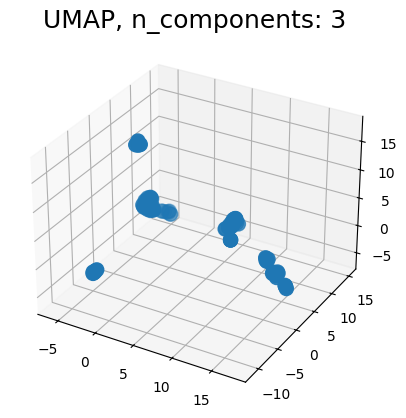

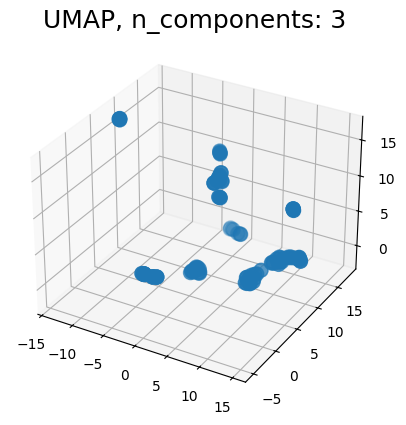

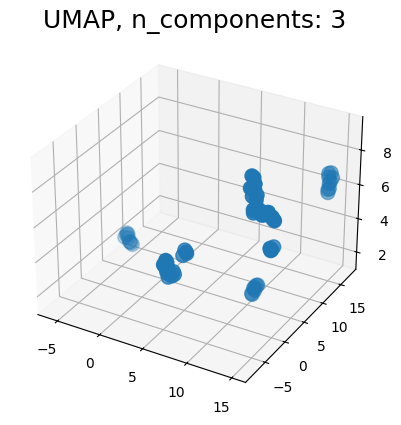

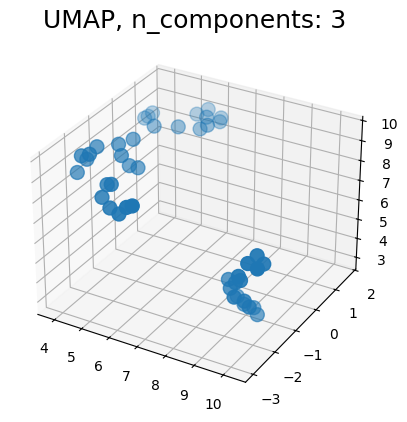

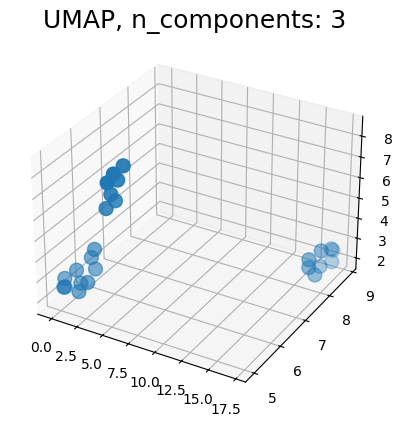

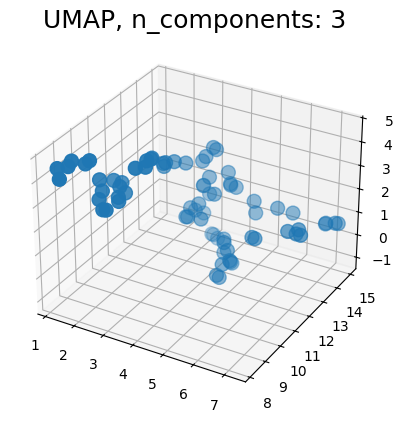

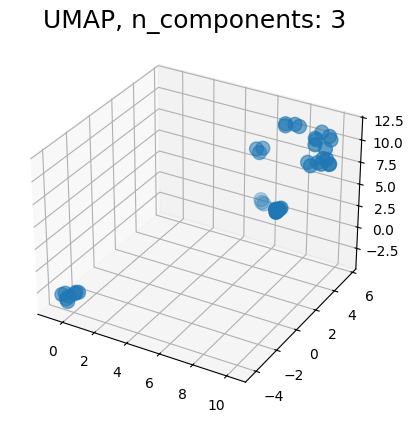

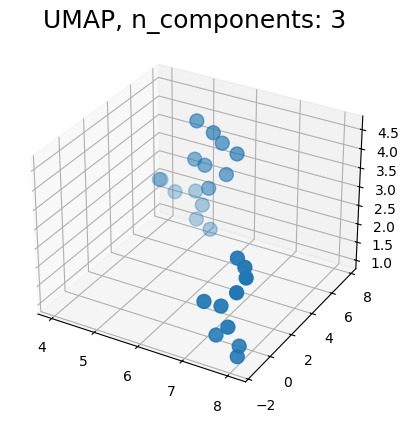

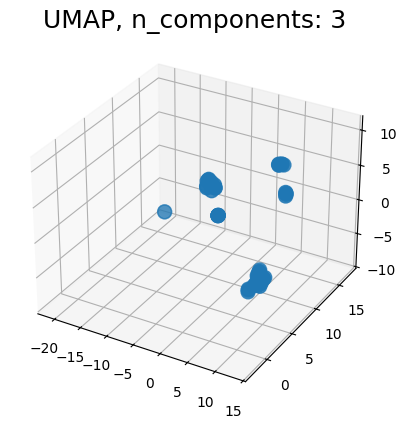

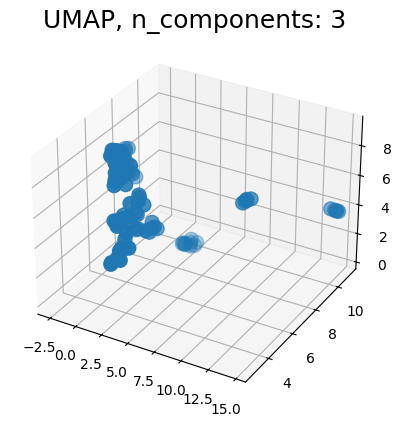

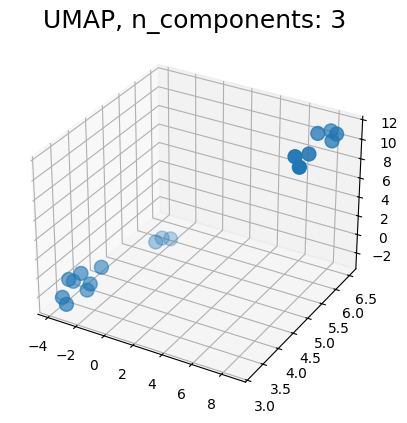

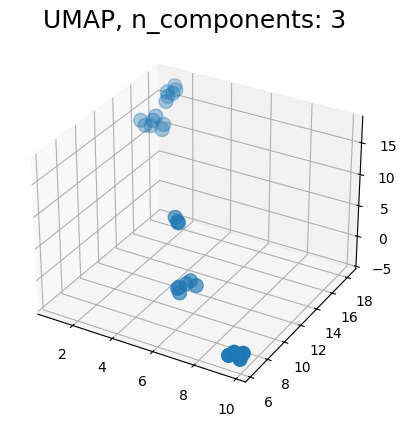

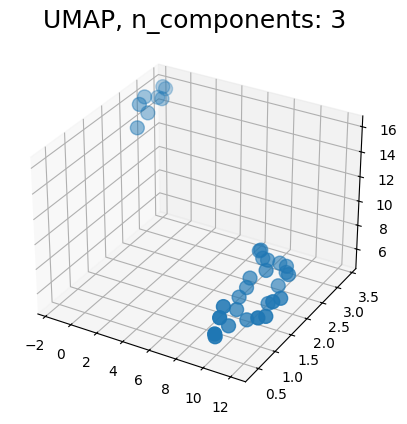

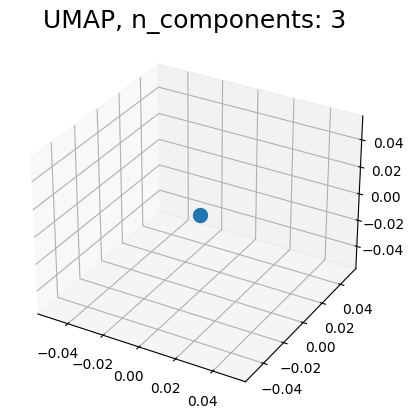

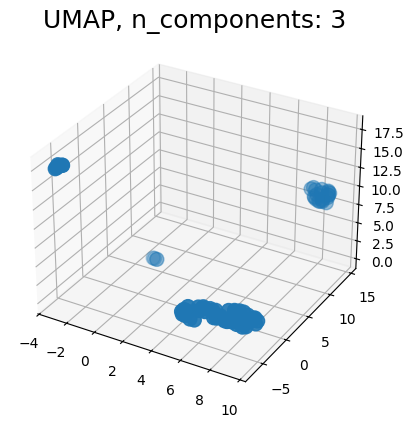

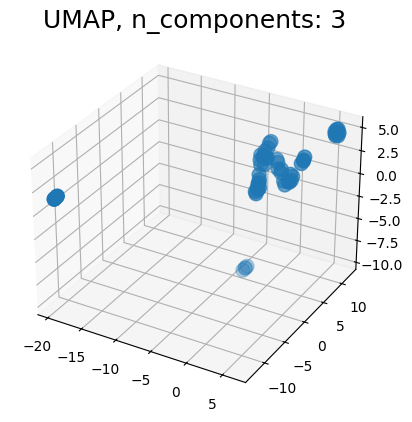

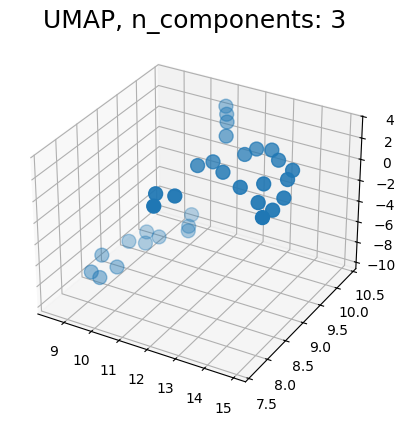

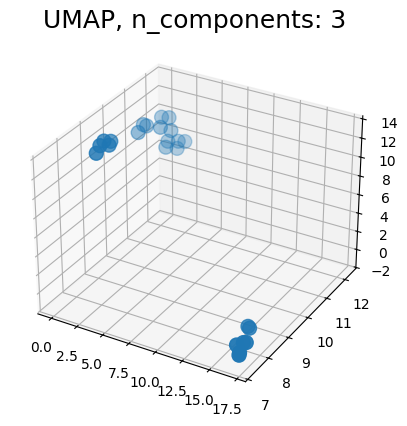

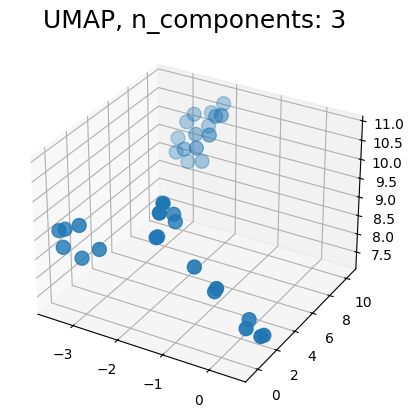

In [20]:
if __name__ == "__main__":

    dfs = main_FPI(dfs)

In [21]:
'''reduced_embeddings = compute_PFI(dfs_company_websites[0], 'umap')
# Plot reduced embeddings
plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], alpha=0.5)
plt.title("Embedding Space Visualization")
plt.show()'''

'reduced_embeddings = compute_PFI(dfs_company_websites[0], \'umap\')\n# Plot reduced embeddings\nplt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], alpha=0.5)\nplt.title("Embedding Space Visualization")\nplt.show()'

We choose UMAP as the used technique since it is far more stable than t-SNE for our dataset

In [22]:
'''embeddings = compute_PFI(dfs_company_websites[0], 'umap')

list_eps = [0.25, 0.4, 0.5, 0.75, 1, 1.5, 2, 2.5, 3, 4]

for eps in list_eps:
    dbscan = DBSCAN(eps=eps, min_samples=2)
    labels = dbscan.fit_predict(embeddings)
    
    try: 
        score = silhouette_score(embeddings, labels)
        print(f'the clustering with eps equal to {eps} has score: {score}')

    except Exception as e:
        print(e)'''

"embeddings = compute_PFI(dfs_company_websites[0], 'umap')\n\nlist_eps = [0.25, 0.4, 0.5, 0.75, 1, 1.5, 2, 2.5, 3, 4]\n\nfor eps in list_eps:\n    dbscan = DBSCAN(eps=eps, min_samples=2)\n    labels = dbscan.fit_predict(embeddings)\n\n    try: \n        score = silhouette_score(embeddings, labels)\n        print(f'the clustering with eps equal to {eps} has score: {score}')\n\n    except Exception as e:\n        print(e)"

after some iterative running of this code we have come to the conclusion that the ideal value for eps with the use of UMAP as the dimensionality reduction technique is: **EPS = 2**

In [32]:
dfs[15].show()

+---+----------+--------------------+------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------+-------------------+--------------------+-------------------+--------------------+--------------------+----------------+--------------------+
|idx|      date|             content|ticker|               title|       content_lemma|         title_lemma|     title_tokenized|   content_tokenized|num_words_title|num_words_content|period_start|period_end|biweekly_period|next_announcement|biweekly_index|     polarity_title|    polarity_content| subjectivity_title|subjectivity_content|  finbert_embeddings|ollama_sentiment|                 FPI|
+---+----------+--------------------+------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------------+--------

25/12/13 18:03:36 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 18:03:36 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 18:03:36 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 18:03:36 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 18:03:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 18:03:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

### Approach B: Embedding drift from financing events
**Steps:**

1. Step One: For all historical financing events, compute the average embedding of the 2 weeks before the financing. This creates the financing Signature Vector
2. For each NEW 2-week window, compute the cosine similarity to this signature. With new we mean that the computed distance is only to the average embedding pf past financing events.

In [23]:
def add_last_announcement_embedding(df_sorted):
    """
    df_sorted must be sorted by 'period' already.
    For each period, emb_last_announcement is the avg_finbert_period
    of the last PREVIOUS financing period.
    If there was no previous financing, emb_last_announcement = None.
    """
    last_embedding = None
    emb_dict = {}

    # group by period, in chronological order
    for period, group in df_sorted.groupby('period', sort=True):
        # assign current last_embedding to all rows of THIS period
        for idx in group.index:
            emb_dict[idx] = last_embedding

        # AFTER assigning, update last_embedding if THIS period has a financing
        if group['next_announcement'].max() == 1:
            # avg_finbert_period is the same for all rows in this period
            last_embedding = group['avg_finbert_period'].iloc[0]

    # map back to original index order
    df_sorted['emb_last_announcement'] = df_sorted.index.map(emb_dict.get)
    return df_sorted

def compute_financing_sim(row):
    if row['emb_last_announcement'] is None:
        return np.nan  # or another placeholder
    return cosine_similarity(
        np.array(row['finbert_arr']).reshape(1, -1),
        np.array(row['emb_last_announcement']).reshape(1, -1)
    )[0][0]


def main_FinSim(list_dfs):
    dfs_with_FinSim = []

    for df in list_dfs:

        try:
            # COMPUTE CLUSTER TABLE WITH PREVIOUS FUNCTION
            df_pandas = compute_PFI(df, 'umap')[['biweekly_period', 'finbert_arr', 'next_announcement']].copy()

            # MAKE PERIOD NUMERIC 
            df_pandas['period'] = df_pandas['biweekly_period'].apply(lambda x: int(x[1:3]) if len(x) == 3 else int(x[1]))
        
            # ADD INDEX VARIABLE FOR LATER MERGING
            df_pandas = df_pandas.reset_index().rename(columns={"index": "idx"})

            # MAKE A NEW DATAFRAME AS COPY
            df_period = df_pandas.copy()

            # COMPUTE THE AVERAGE EMBEDDING PER PERIOD
            df_period= (
                df_pandas.groupby(by=["period", "next_announcement"])["finbert_arr"] \
                        .apply(lambda arrs: mean_array(list(arrs))) \
                        .reset_index(name='avg_finbert_period')
            )

        
            df_pandas = df_pandas.merge(df_period[['period', 'avg_finbert_period']], on='period', how='left')

            df_sorted = df_pandas.sort_values(by='period', ascending=True)

            df_last_announcement = add_last_announcement_embedding(df_sorted)

            # COMPUTE cosine similarity to last financing event 
            df_last_announcement['Financing_sim']= df_last_announcement.apply(compute_financing_sim, axis=1)

            # Merge with df
            df_pandas = df_pandas.merge(df_last_announcement[['idx', 'Financing_sim']], on= ['idx'], how='left')[['idx', 'Financing_sim']]


            # JOIN TO SPARK DF
            w = Window.orderBy(F.lit(1))
            df_FinSim = spark.createDataFrame(df_pandas) 
            df = df.withColumn('idx', F.row_number().over(w))
            joined_df = df.join(df_FinSim, on='idx', how="inner")
            print("OK")
        
        except Exception as e:
            df = df.withColumn('Financing_sim', F.lit(np.nan))
            joined_df = df
            print(f'Not Enough Articles Found, error: {e}')

        dfs_with_FinSim.append(joined_df)

    return dfs_with_FinSim

25/12/13 15:37:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

ConnectionRefusedError: [Errno 61] Connection refused

25/12/13 15:37:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:41 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

OK


25/12/13 15:37:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:42 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

OK


... (20 outputs left out)

25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

OK


25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:45 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

OK


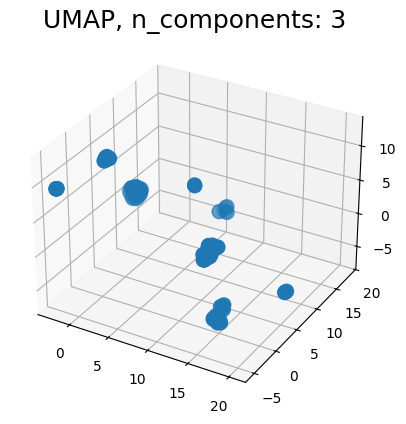

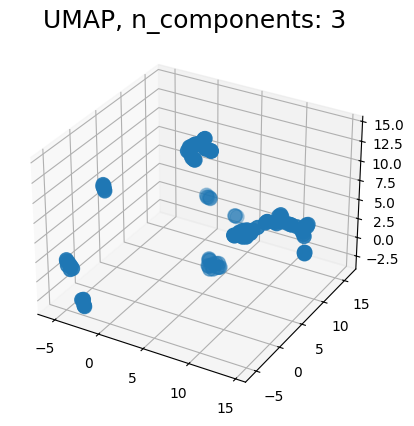

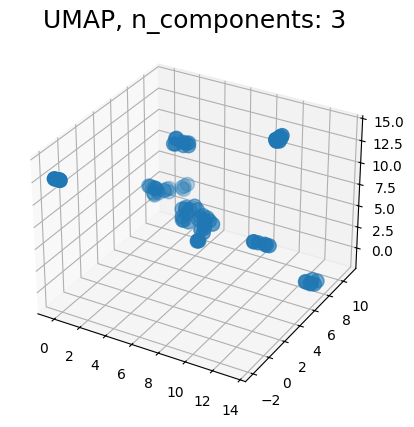

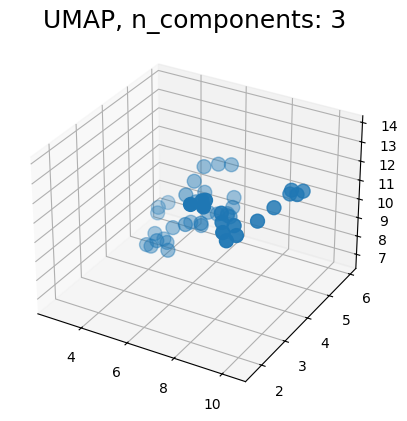

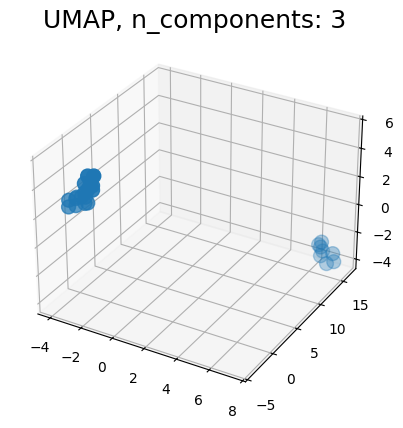

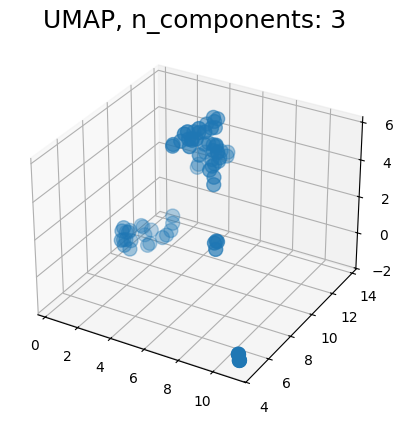

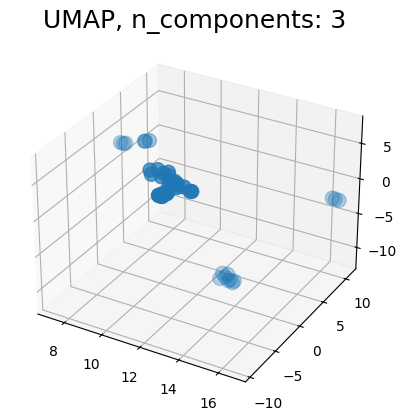

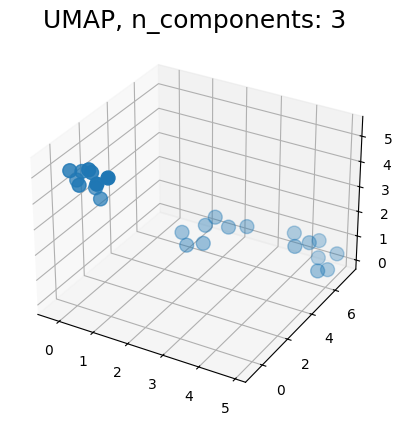

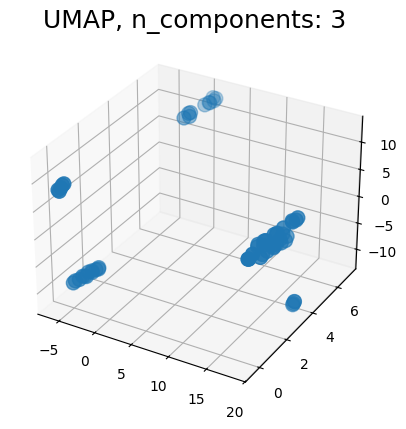

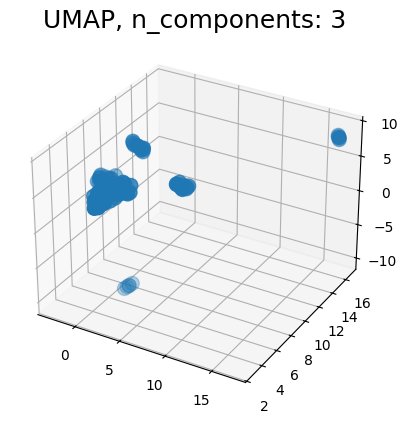

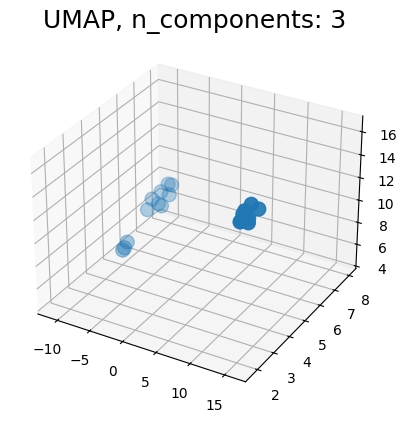

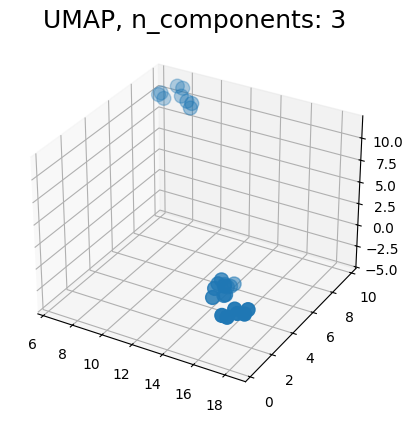

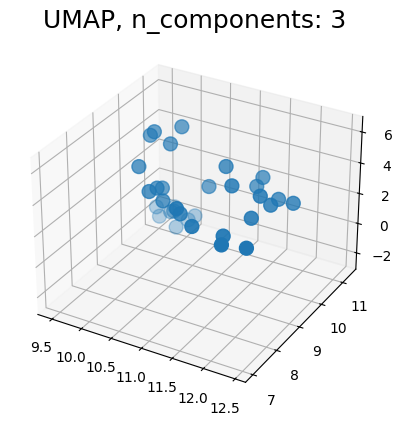

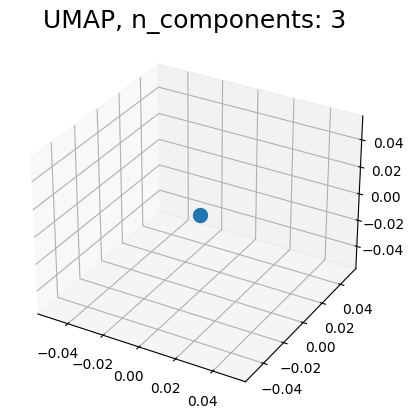

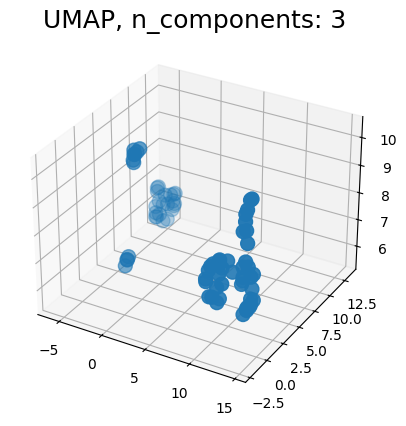

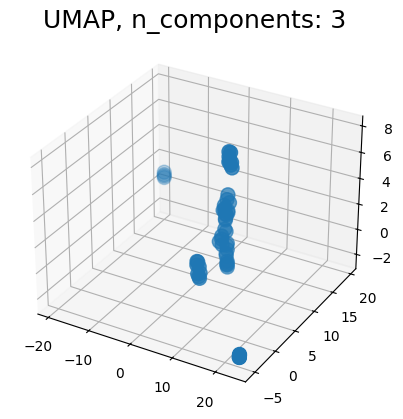

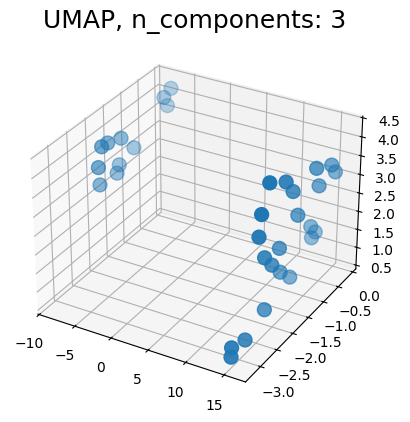

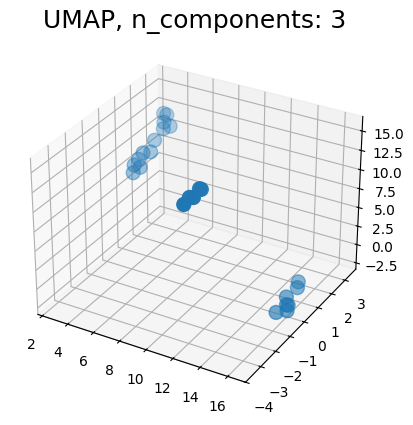

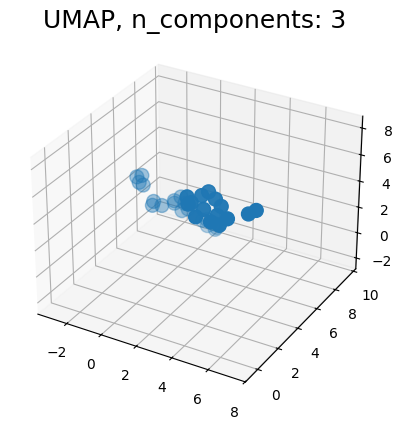

In [24]:
if __name__ == "__main__":

    dfs = main_FinSim(dfs)

In [25]:
basetables[12].show(50)

25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

+---+----------+--------------------+------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------+--------------------+--------------------+-------------------+--------------------+--------------------+----------------+--------------------+------------------+
|idx|      date|             content|ticker|               title|       content_lemma|         title_lemma|     title_tokenized|   content_tokenized|num_words_title|num_words_content|period_start|period_end|biweekly_period|next_announcement|biweekly_index|      polarity_title|    polarity_content| subjectivity_title|subjectivity_content|  finbert_embeddings|ollama_sentiment|                 FPI|     Financing_sim|
+---+----------+--------------------+------+--------------------+--------------------+--------------------+--------------------+--------------------+---------------

In [20]:
dfs[17].show(50)

25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:46 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

In [26]:
for i, df in enumerate(dfs):
    df.write.mode("overwrite").parquet(f"./Intermediate_data/df_{i}.parquet")

25/12/13 15:37:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 15:37:47 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
25/12/13 1

# Basetable 

In [27]:
def safe_expr(expr):
    try:
        return expr
    except Exception:
        return F.lit(np.nan)

# -------------------------------------------------------
# Main aggregation function
# -------------------------------------------------------

def aggregate_sentiment(df):

    agg_sent = (
        df
        .groupBy(
            [F.col("biweekly_period"),
            F.col("biweekly_index")]
        )
        .agg(
            # DEPENDENT VARIABLE
            F.mode('next_announcement').alias("next_announcement"),

            # GENERAL ARTICLE FEATURES 
            F.count("*").alias("n_artices"),
            F.avg('num_words_title').alias("avg_num_words_title"), 
            F.avg('num_words_content').alias("avg_num_words_content"), 

            # POLARITY AND SUBJECTIVITY FEATURES
            F.avg("polarity_title").alias("avg_polarity_title"),
            F.avg("polarity_content").alias("avg_polarity_content"),
            F.avg("subjectivity_title").alias("avg_subjectivity_title"),
            F.avg("subjectivity_content").alias("avg_subjectivity_content"),

            # OLLAMA SENTIMENT FEATURES 
            safe_expr(F.avg("ollama_sentiment").alias("avg_ollama")),
            safe_expr(F.stddev_pop("ollama_sentiment").alias("std_ollama")),
            safe_expr(F.min("ollama_sentiment").alias("min_ollama")),
            safe_expr(F.max("ollama_sentiment").alias("max_ollama")),

            # EMBEDDING FEATURES ...
            F.collect_list("finbert_arr").alias("finbert_arr_list")
        )
    )

    agg_sent = (
        agg_sent
        .withColumn("avg_finbert_array", mean_array_udf("finbert_arr_list"))
        .drop("finbert_arr_list")
    )

    agg_sent = agg_sent.withColumn(
        "avg_finbert_vec",
        to_vec_udf("avg_finbert_array")
    )
    
    return agg_sent


def main_basetable(dfs_list): 

    dfs_basetable = []

    for df in dfs_list:
        basetable = aggregate_sentiment(df).cache()

        dfs_basetable.append(basetable)

    return dfs_basetable
    

In [28]:
if __name__ == "__main__":

    dfs = main_basetable(dfs)

25/12/13 15:37:53 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
{"ts": "2025-12-13 15:37:53.385", "level": "ERROR", "logger": "DataFrameQueryContextLogger", "msg": "[UNRESOLVED_COLUMN.WITH_SUGGESTION] A column, variable, or function parameter with name `finbert_arr` cannot be resolved. Did you mean one of the following? [`content`, `ticker`, `date`, `idx`, `title`]. SQLSTATE: 42703", "context": {"file": "jdk.internal.reflect.GeneratedMethodAccessor10.invoke(Unknown Source)", "line": "", "fragment": "col", "errorClass": "UNRESOLVED_COLUMN.WITH_SUGGESTION"}, "exception": {"class": "Py4JJavaError", "msg": "An error occurred while calling o9593.agg.\n: org.apache.spark.sql.AnalysisException: [UNRESOLVED_COLUMN.WITH_SUGGESTION] A column, variable, or function parameter with name `finbert_arr` cannot be resolved. Did you mean one of the following? [`content`, `ticker`,

AnalysisException: [UNRESOLVED_COLUMN.WITH_SUGGESTION] A column, variable, or function parameter with name `finbert_arr` cannot be resolved. Did you mean one of the following? [`content`, `ticker`, `date`, `idx`, `title`]. SQLSTATE: 42703;
'Aggregate [biweekly_period#2, biweekly_index#1], [biweekly_period#2, biweekly_index#1, mode(next_announcement#37, 0, 0, None) AS next_announcement#69512, count(1) AS n_artices#69513L, avg(num_words_title#93) AS avg_num_words_title#69514, avg(num_words_content#94) AS avg_num_words_content#69515, avg(polarity_title#6103) AS avg_polarity_title#69516, avg(polarity_content#6105) AS avg_polarity_content#69517, avg(subjectivity_title#6107) AS avg_subjectivity_title#69518, avg(subjectivity_content#6109) AS avg_subjectivity_content#69519, avg(cast(ollama_sentiment#26236 as double)) AS avg_ollama#69520, stddev_pop(cast(ollama_sentiment#26236 as double)) AS std_ollama#69521, min(ollama_sentiment#26236) AS min_ollama#69522, max(ollama_sentiment#26236) AS max_ol

# To Do
* avg, min, max, std of ollama sentiment **OK**
* maybe check other models (ollama, or others)
* TextBlob **OK, except for word2vec**
* other preprocessing steps **OK**
    - remove urls, numbers (anything stock price related, financial results, etc.), stock tickers,
    - stemming/lemmatization 
        - create a column in the dataframe with lemmatized content. (only for TextBlob)
    - removing special characters
* UDF to get an average embedding (avg of multiple arrays) **OK**
* think about other use case for the embeddings
    - Financing pressure index
    - Semantic change detection
    - Embedding-Based “Narrative Similarity” to Past Financing Events
    - (Clustering news in themes)
* topic modeling and summerization

* Creating a basetable (don't forget the ticker and period for later merging) **DOING**
* Merge with augmented data, whenever dependent variable was added. in stead of biweekly_data.parquet

* Small modeling case **COPY PASTE (& ADD XGBOOST)**


In [5]:
df = spark.read.parquet(
    "/Users/douwepauwels/Downloads/Big_Data/Groupwork/Big_data_group_2/Cleaned_data/basetable_company_sentiment.parquet"
)

Row(biweekly_index=0, next_announcement=0, n_artices=1, avg_num_words_title=7.0, avg_num_words_content=709.0, avg_polarity_title=0.0, avg_polarity_content=0.0318452380952381, avg_subjectivity_title=0.0, avg_subjectivity_content=0.42693452380952385, avg_ollama=0.75, std_ollama=0.0, min_ollama='0.75', max_ollama='0.75', avg_FPI=0.8744428928091922, std_FPI=0.0, avg_Financing_sim=0.0, avg_finbert_array=[-0.04620778188109398, 0.4354929029941559, 0.025263488292694092, -0.020556967705488205, -0.0016037514433264732, 0.3632877469062805, 0.43929582834243774, -0.04964565485715866, 0.5369528532028198, -0.17606686055660248, -0.014294750057160854, -0.2521602213382721, 0.031652361154556274, 0.05916193127632141, 0.1893988847732544, 0.6368428468704224, -0.19175985455513, -0.2871473729610443, -0.5893434882164001, 0.6676429510116577, 0.20655544102191925, 0.3166508674621582, 0.6029651165008545, 0.408378005027771, -0.1566876769065857, 0.05302710086107254, -0.14999927580356598, -0.6223549842834473, -0.61558

In [10]:
df.show()

+--------------+-----------------+---------+-------------------+---------------------+-------------------+--------------------+----------------------+------------------------+--------------------+------------------+----------+----------+------------------+--------------------+-----------------+--------------------+--------------------+------+------------------+-------------------+--------------------+------------------+
|biweekly_index|next_announcement|n_artices|avg_num_words_title|avg_num_words_content| avg_polarity_title|avg_polarity_content|avg_subjectivity_title|avg_subjectivity_content|          avg_ollama|        std_ollama|min_ollama|max_ollama|           avg_FPI|             std_FPI|avg_Financing_sim|   avg_finbert_array|     avg_finbert_vec|ticker|         accum_FPI|  std_avg_FPI_last3|        prev_std_FPI|      prev_avg_FPI|
+--------------+-----------------+---------+-------------------+---------------------+-------------------+--------------------+----------------------+--

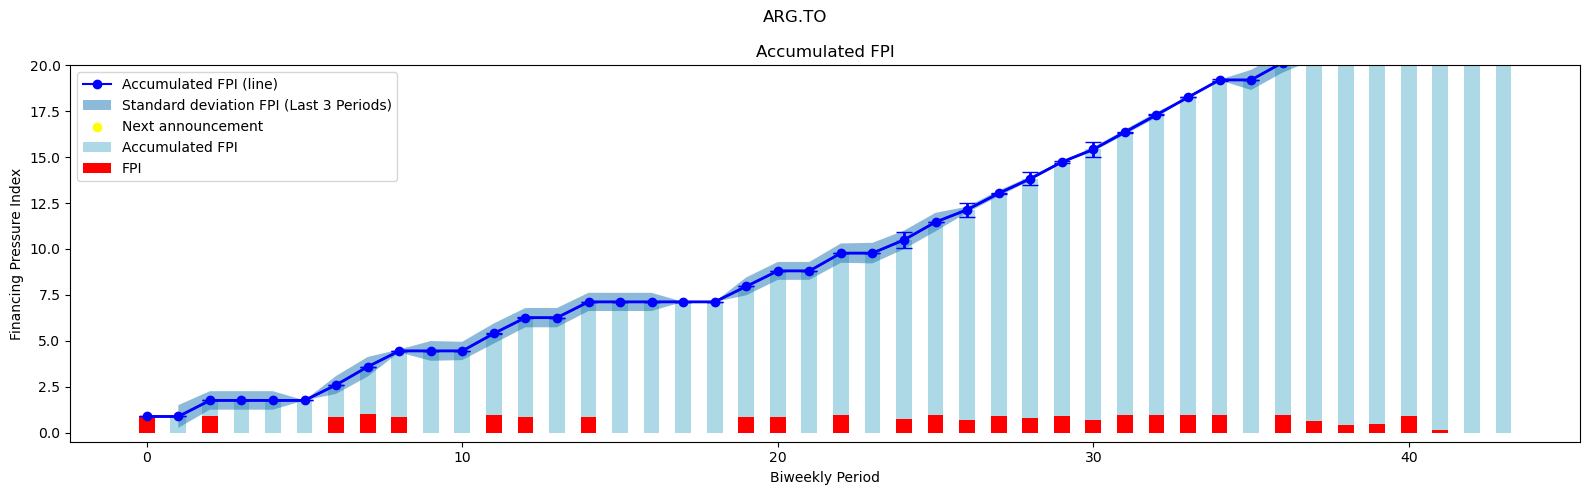

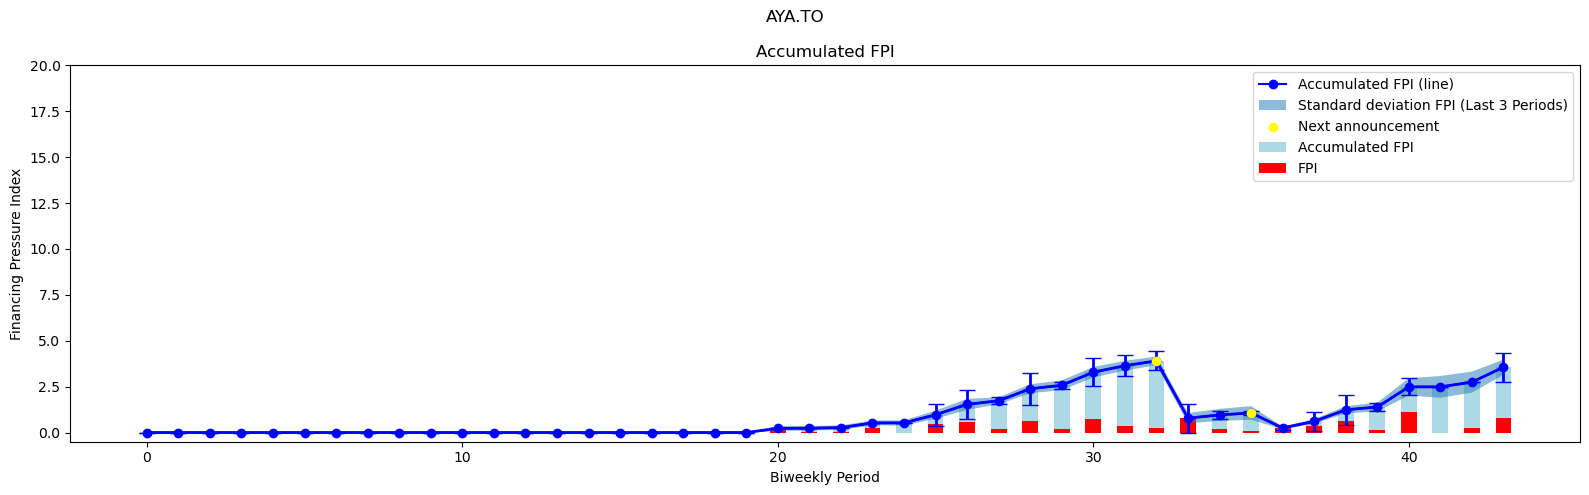

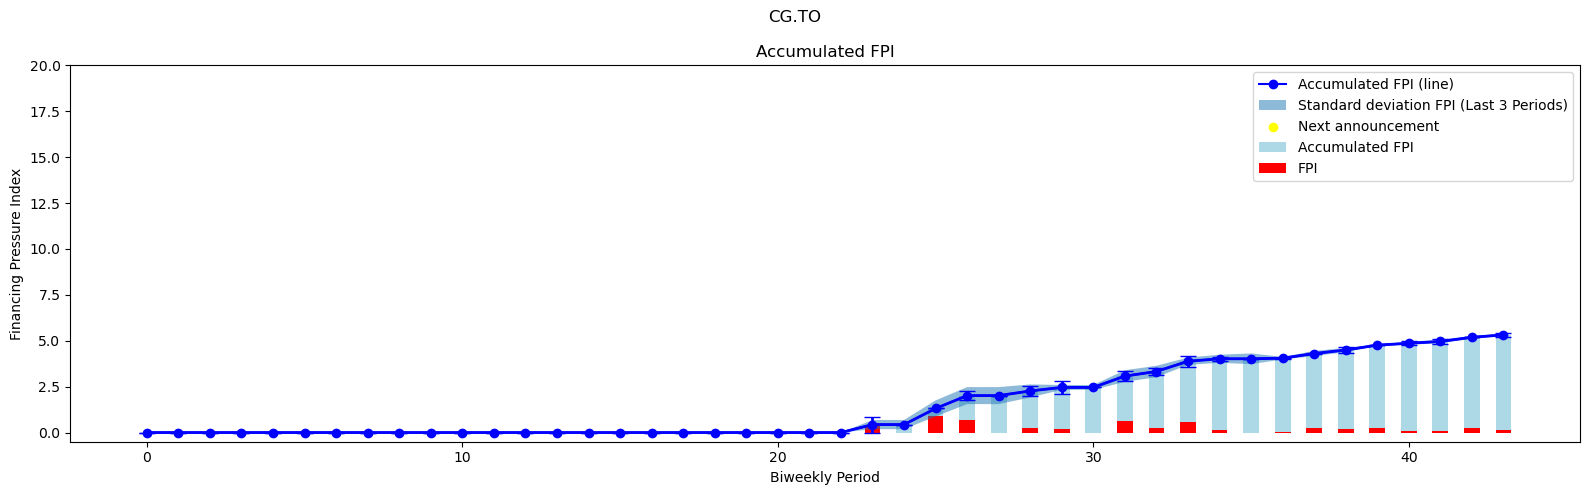

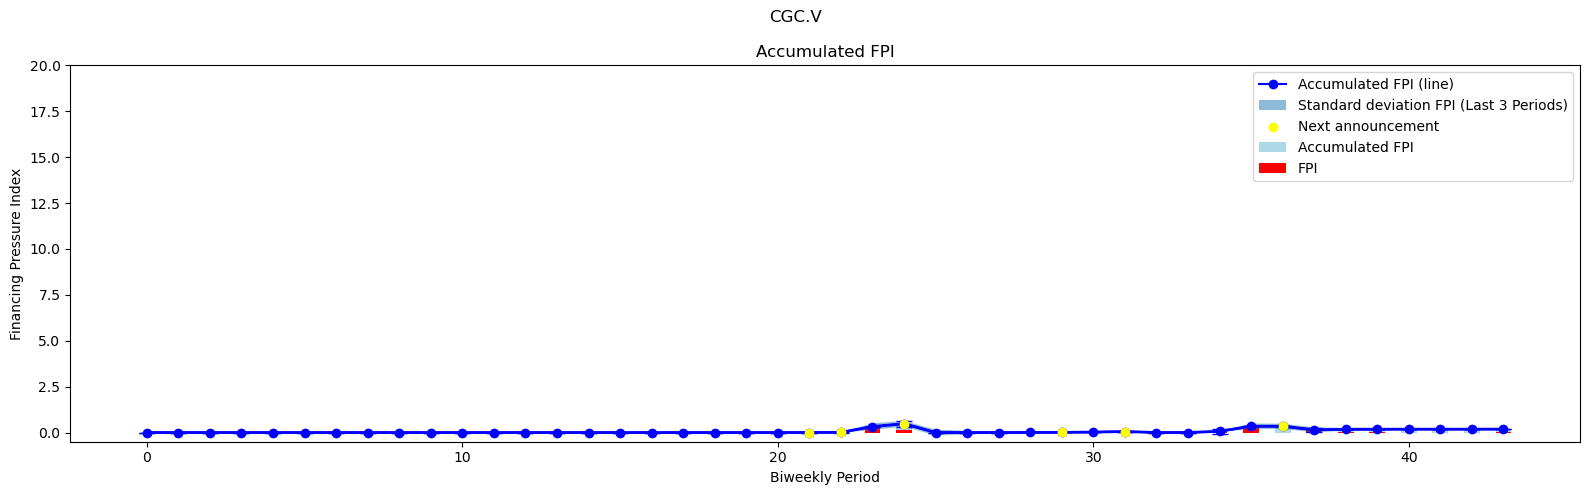

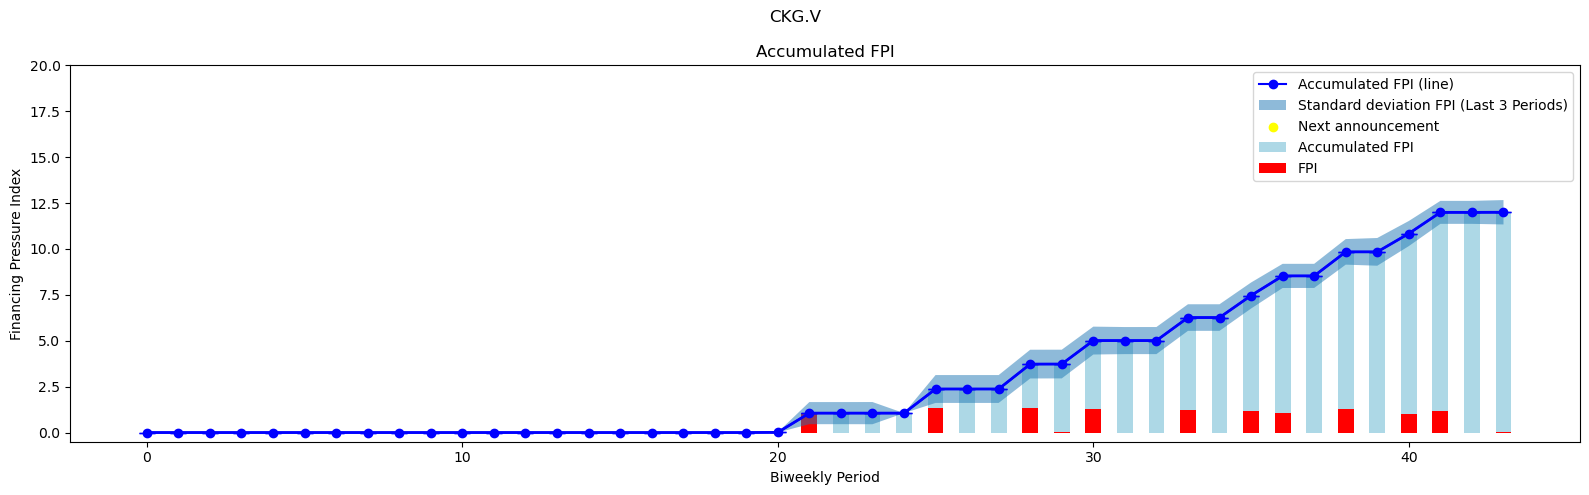

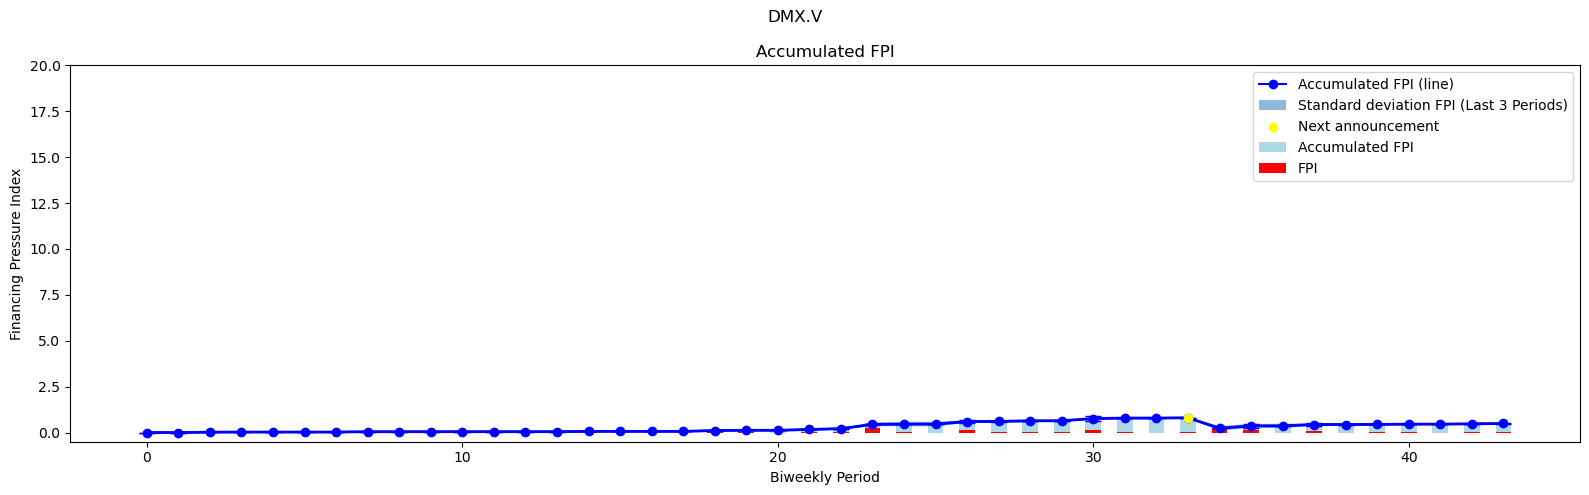

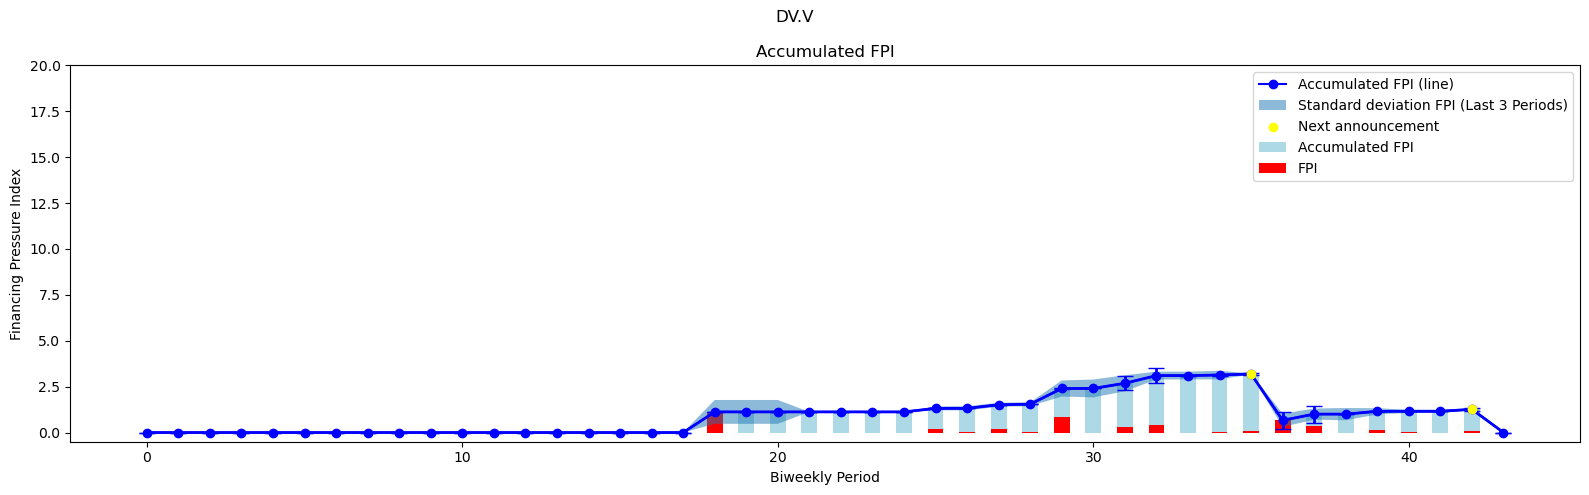

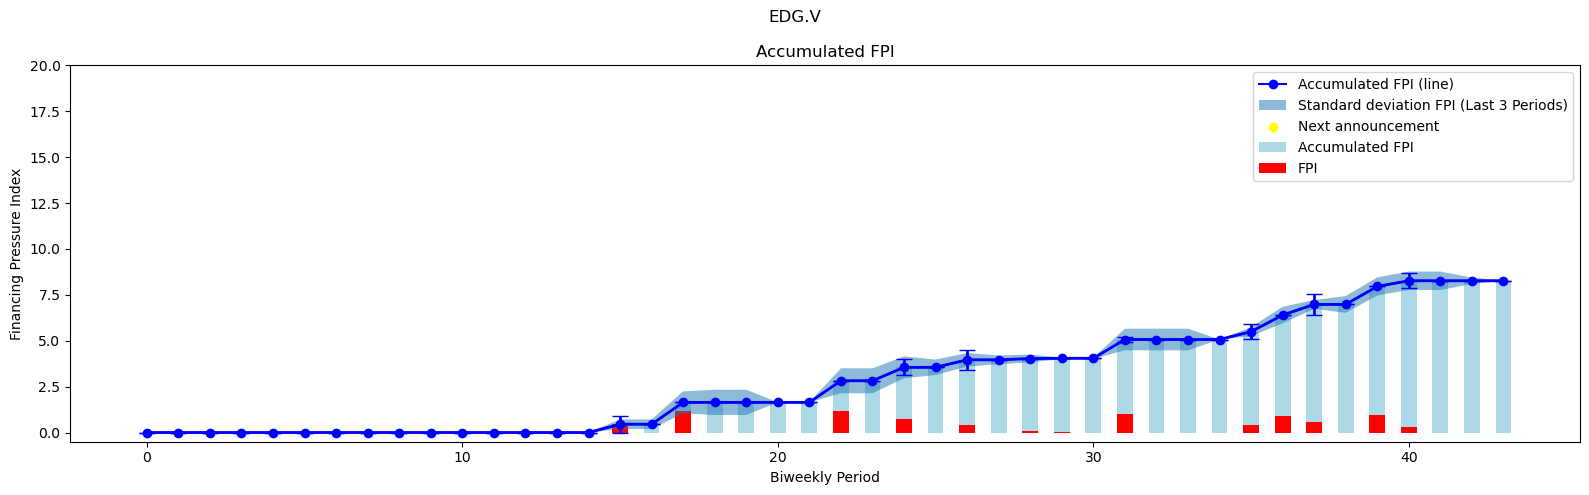

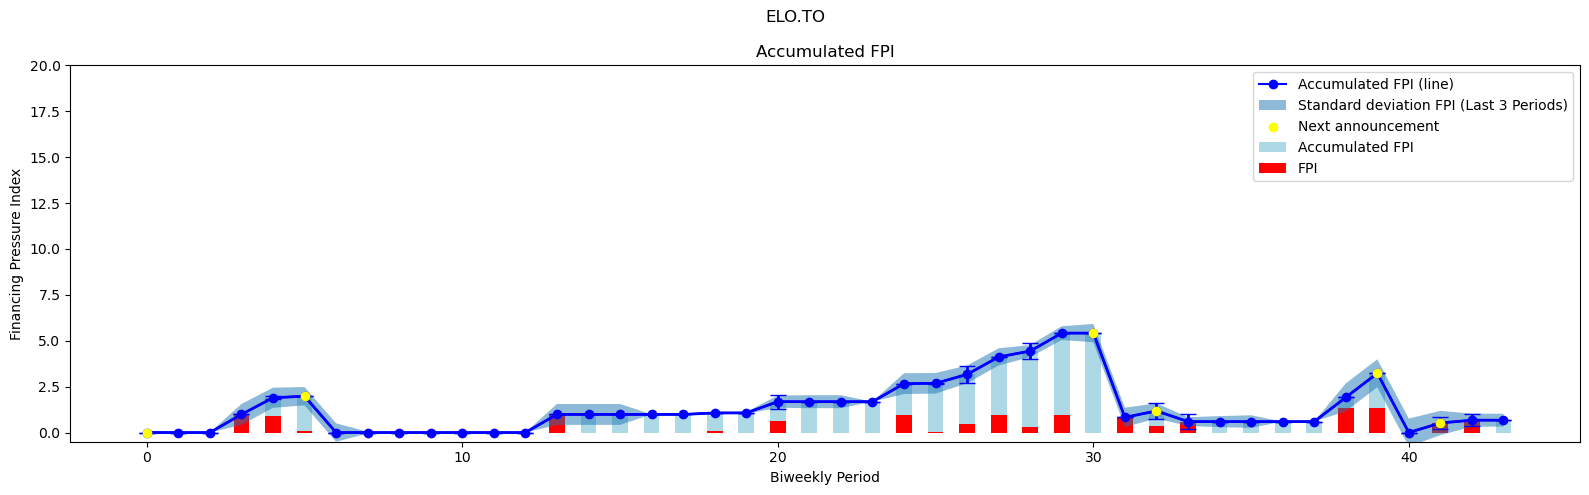

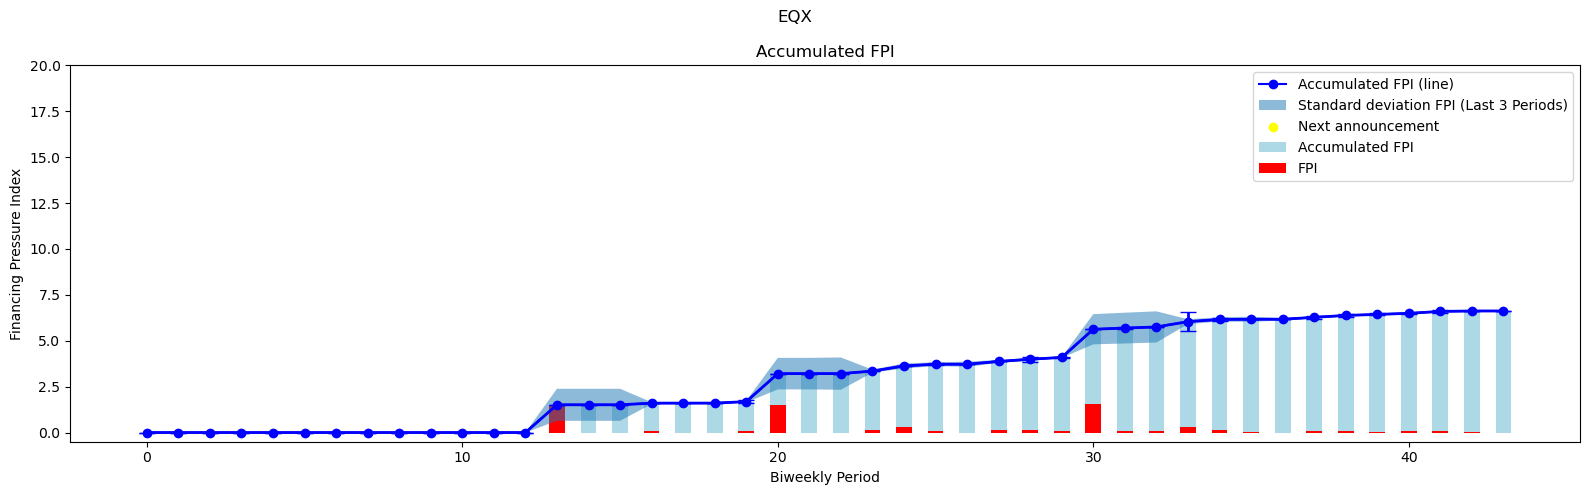

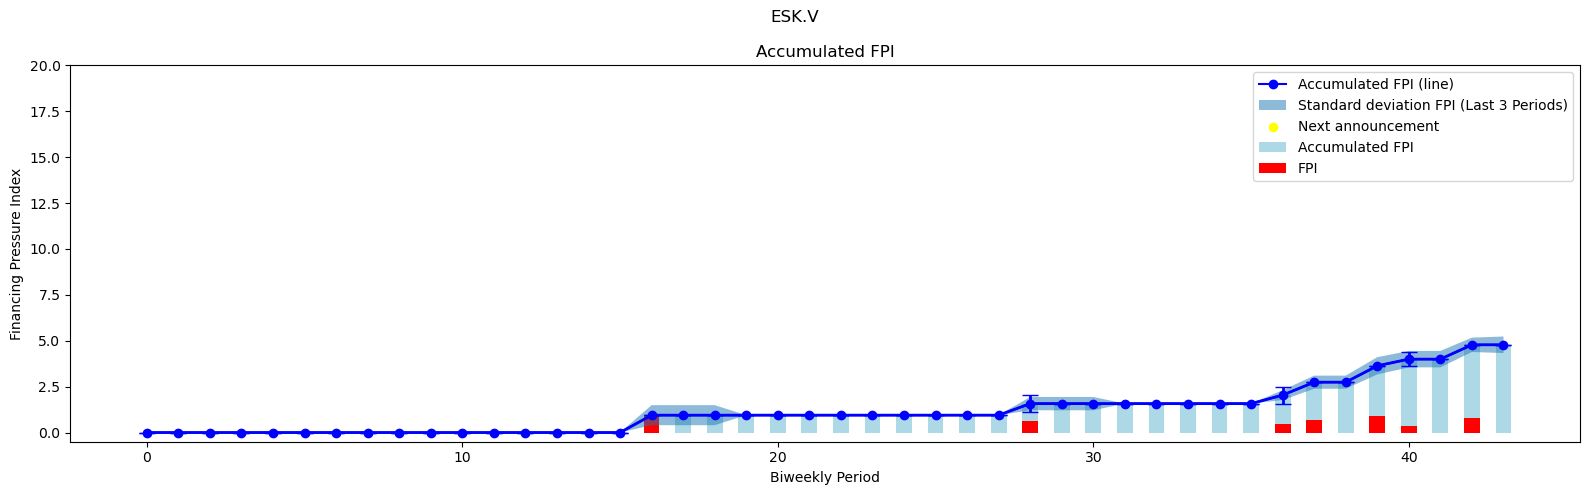

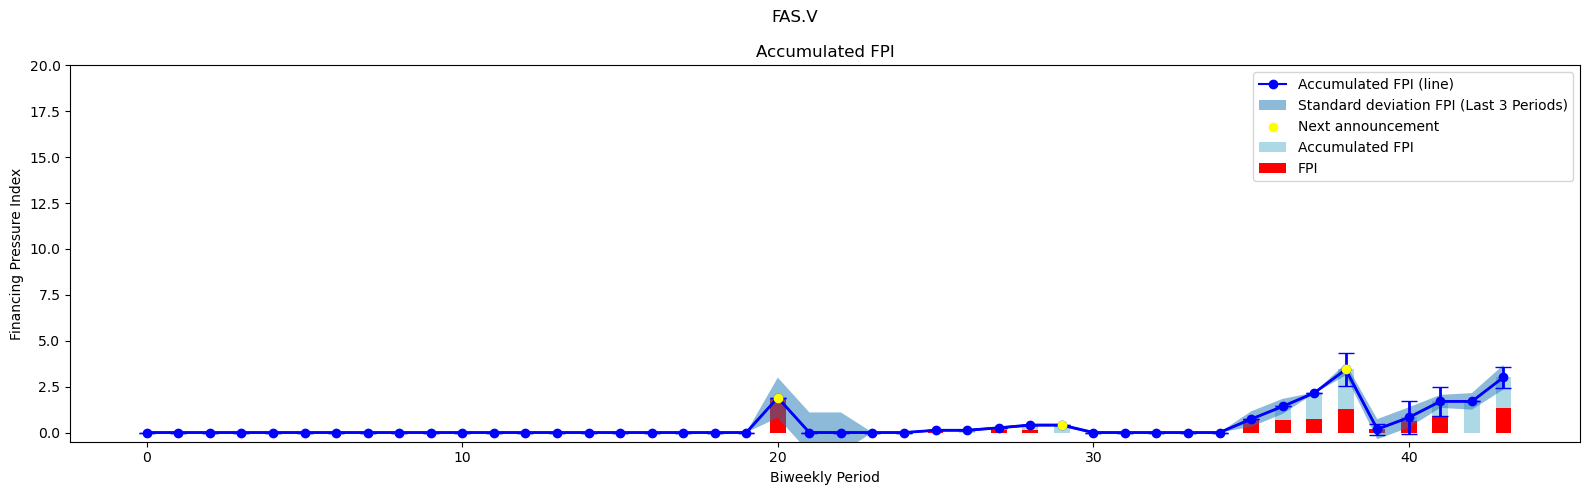

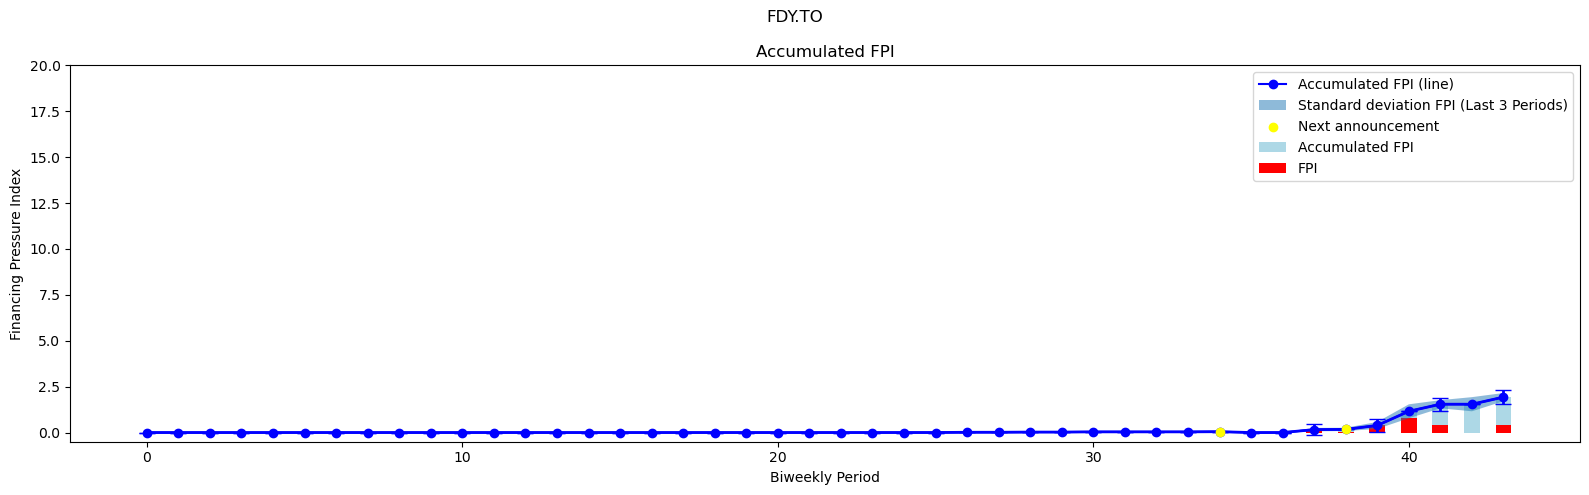

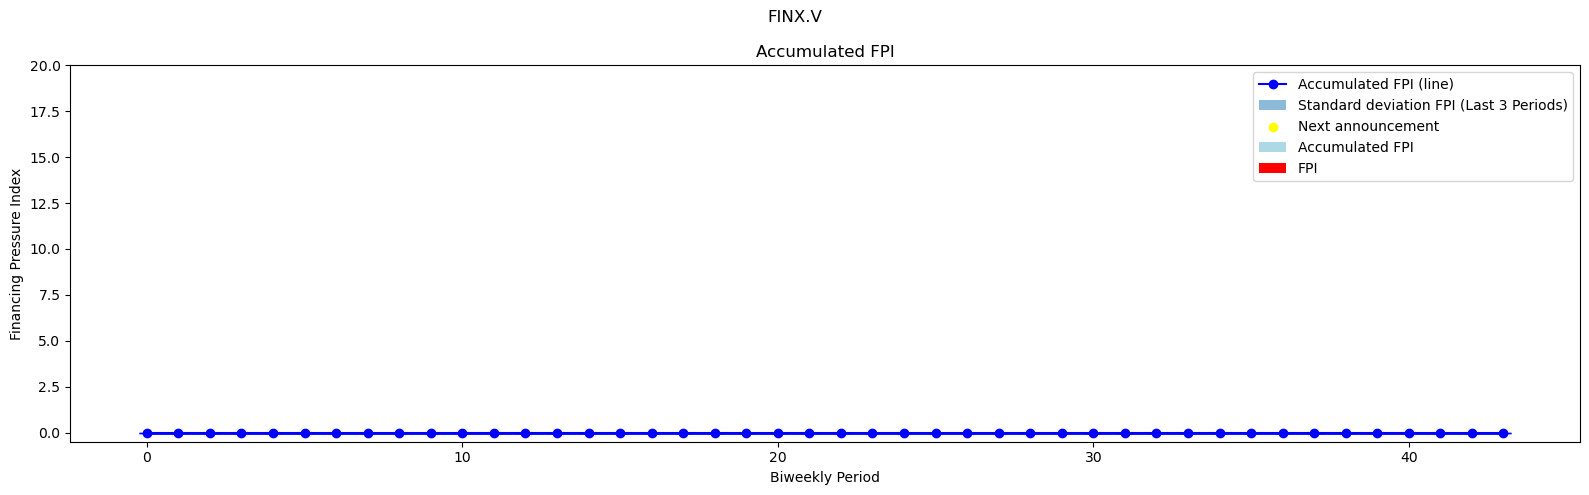

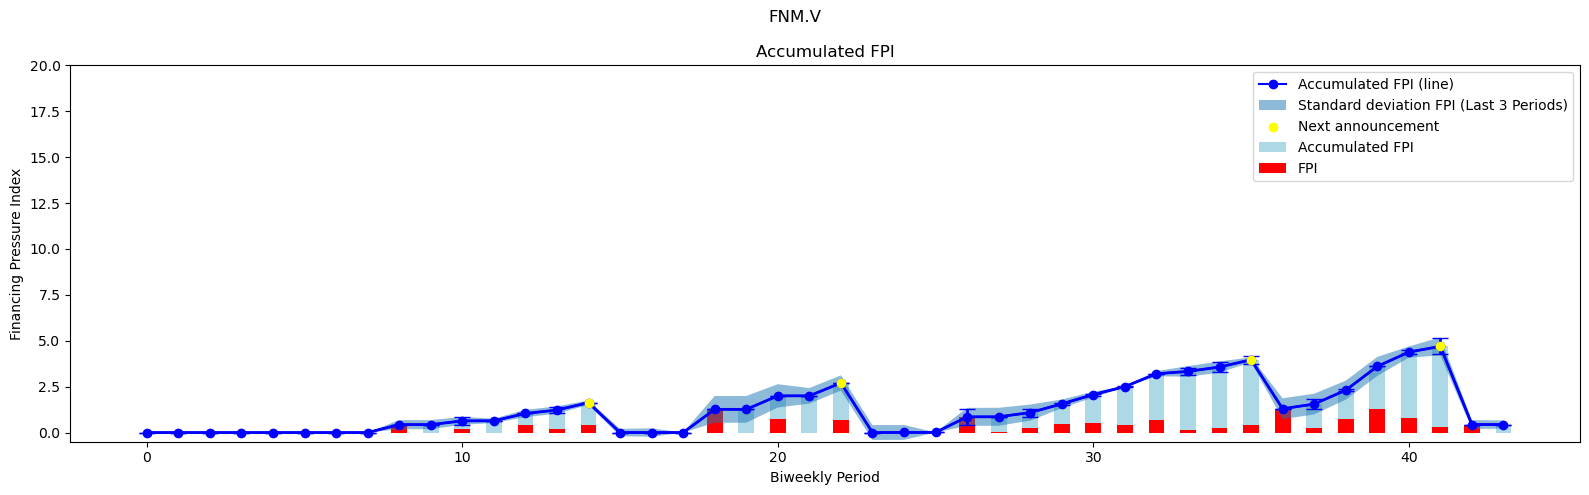

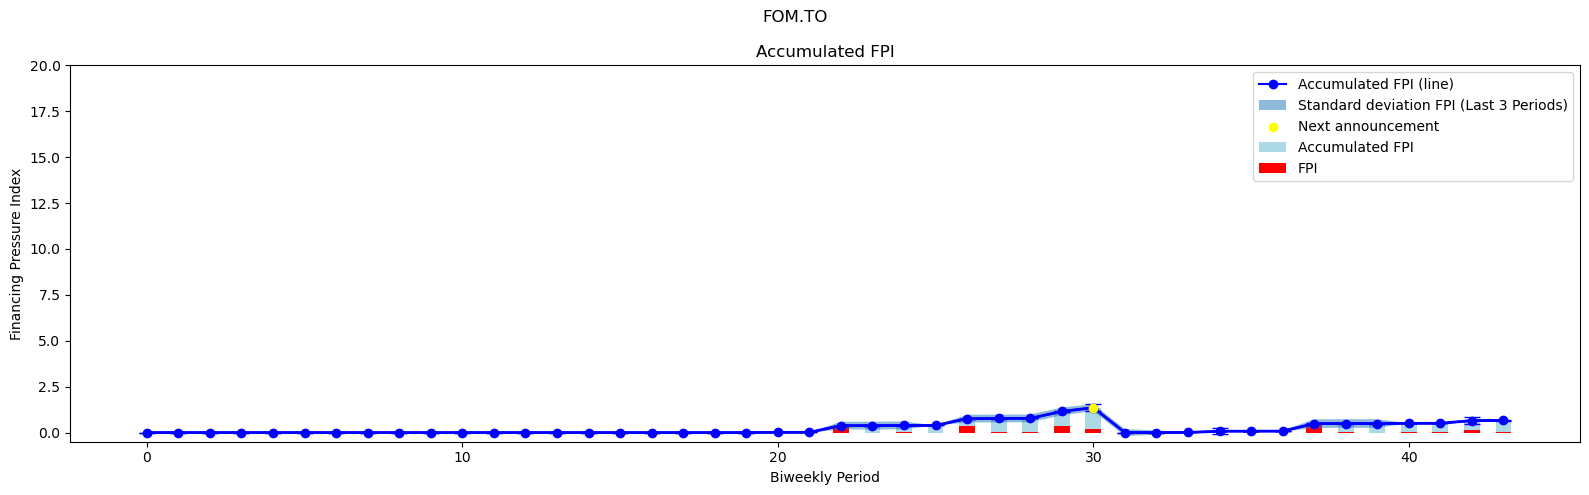

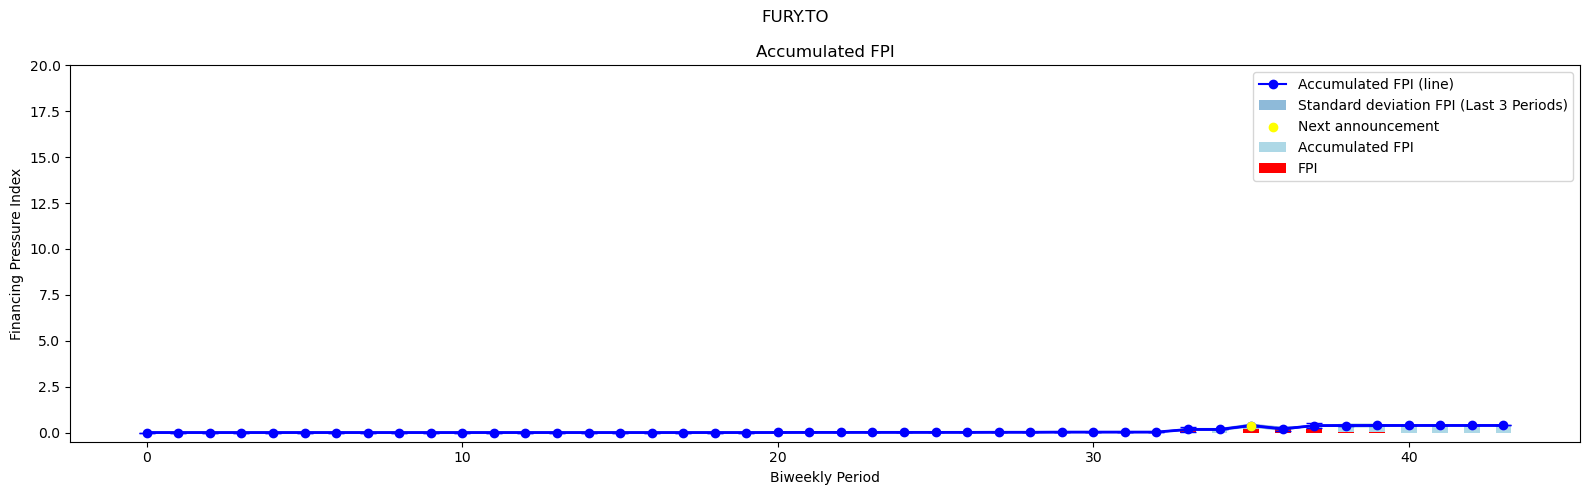

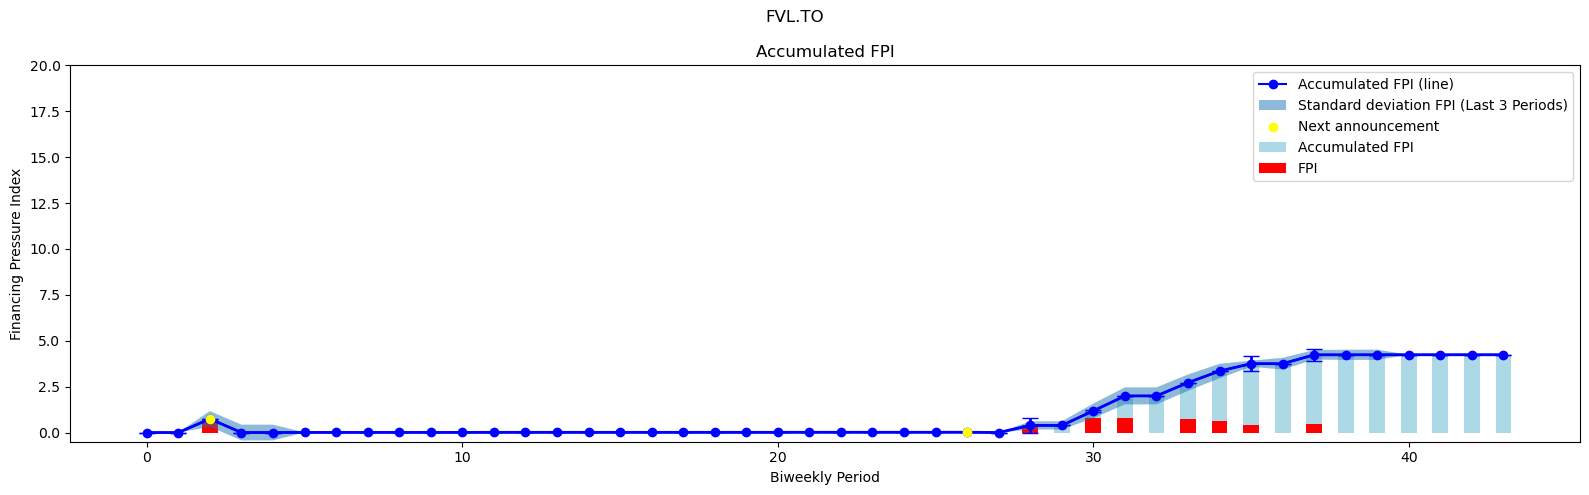

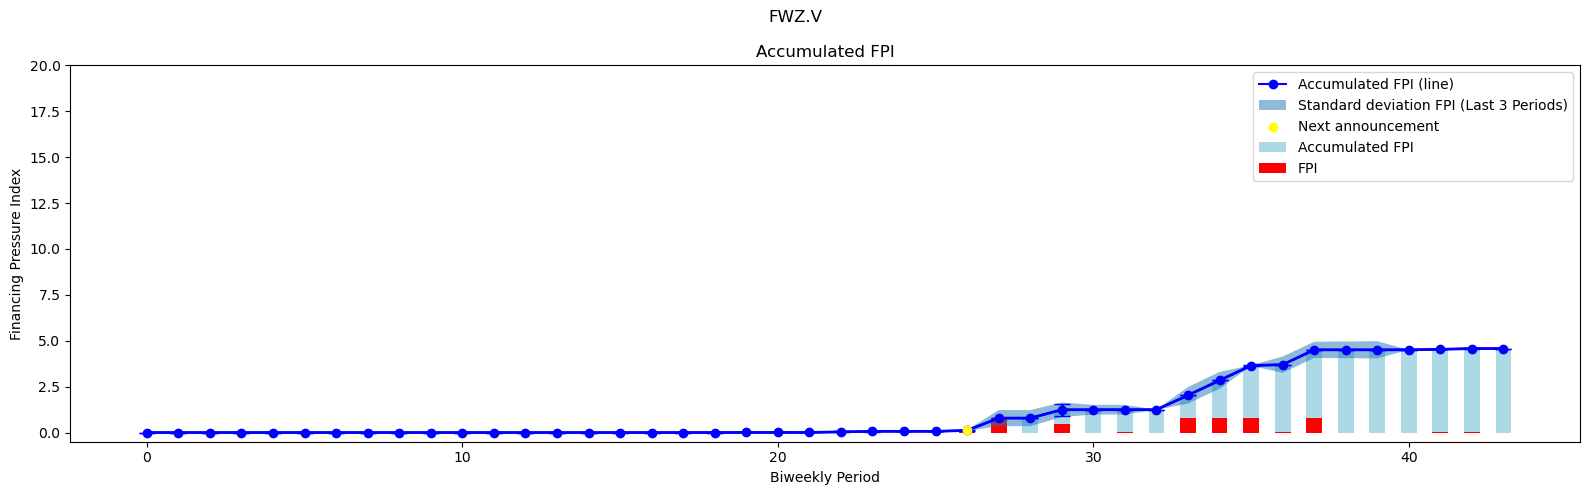

In [19]:
df = df.toPandas()
# plotting 
for ticker in tickers_df["tickers"].tolist():
    dft = df[df["ticker"] == ticker].sort_values("biweekly_index")

    # Use the actual x values (same length as series)\n",
    x = dft["biweekly_index"].to_numpy()
    fpi = dft["accum_FPI"].to_numpy()
    raw_fpi = dft["avg_FPI"].to_numpy()
    fsim = dft["avg_Financing_sim"].to_numpy()
    ann = dft["next_announcement"].to_numpy().astype(int)
    std_fpi = dft['std_FPI'].to_numpy()
    std_fpi_last3 = dft['std_avg_FPI_last3'].to_numpy()

    fig, (ax1) = plt.subplots(1, 1, figsize=(16, 5), sharex=True)
    fig.suptitle(ticker)

    # --- Subplot 1: accumulated FPI ---\n",
    ax1.errorbar(x, fpi, yerr=std_fpi, c='Blue', linewidth=2, capsize=6)
    ax1.bar(x, fpi, width=0.5, color='lightBlue', label="Accumulated FPI")
    ax1.bar(x, raw_fpi, color='Red', width=0.5, label="FPI")
    ax1.plot(x, fpi, "-o", c='Blue', label="Accumulated FPI (line)")
    ax1.fill_between(
        x,
        fpi - std_fpi_last3,
        fpi + std_fpi_last3,
           alpha=0.5,
          label="Standard deviation FPI (Last 3 Periods)"
    )
    ax1.set_xlabel("Biweekly Period")
    ax1.set_ylabel("Financing Pressure Index")
    ax1.set_ylim((-0.5, 20))
    ax1.set_title("Accumulated FPI")

    # Red dots where next_announcement == 1\n",
    mask = ann == 1
    ax1.scatter(x[mask], fpi[mask], label="Next announcement", c='Yellow', zorder=5)
 
    ax1.legend()
    '''# --- Subplot 2: F_SIM ---\n",
    ax2.bar(x, fsim, width=0.5, label=\"avg_Financing_sim\")\n",
    ax2.plot(x, fsim, \"-o\", label=\"avg_Financing_sim (line)\")\n",
    ax2.set_xlabel(\"Biweekly Period\")\n",
    ax2.set_ylabel(\"Financing sim\")\n",
    ax2.set_ylim((-0.5, 1.5))
    ax2.set_title("F_SIM")
    "\n",
    # Red dots where next_announcement == 1\n",
    ax2.scatter(x[mask], fsim[mask], label="Next announcement", c='Red', zorder=5)

    ax2.legend()'''
    plt.tight_layout()
    plt.show()

In [17]:
basetable = (
    df.withColumn("max_ollama", F.col("max_ollama").cast("float"))
      .withColumn("min_ollama", F.col("min_ollama").cast("float"))
)

# Use the first 2/3 of the data for training and the last 1/3 for testing
train_size = int(basetable.count() * 0.67)
train_df = basetable.limit(train_size)

# Use the remaining data for testing
test_df = basetable.subtract(train_df)

In [18]:
# get all numeric columns
numeric_cols = [c for c, t in train_df.dtypes if isinstance(train_df.schema[c].dataType, NumericType)]

# count null values in each column
null_counts_train = train_df.select([F.count(F.when(F.col(c).isNull() | F.isnan(c), c)).alias(c) for c in numeric_cols])
null_counts_train.show()

null_counts_test = test_df.select([F.count(F.when(F.col(c).isNull() | F.isnan(c), c)).alias(c) for c in numeric_cols])
null_counts_test.show()

+--------------+-----------------+---------+-------------------+---------------------+------------------+--------------------+----------------------+------------------------+----------+----------+----------+----------+-------+-------+-----------------+---------+-----------------+------------+------------+
|biweekly_index|next_announcement|n_artices|avg_num_words_title|avg_num_words_content|avg_polarity_title|avg_polarity_content|avg_subjectivity_title|avg_subjectivity_content|avg_ollama|std_ollama|min_ollama|max_ollama|avg_FPI|std_FPI|avg_Financing_sim|accum_FPI|std_avg_FPI_last3|prev_std_FPI|prev_avg_FPI|
+--------------+-----------------+---------+-------------------+---------------------+------------------+--------------------+----------------------+------------------------+----------+----------+----------+----------+-------+-------+-----------------+---------+-----------------+------------+------------+
|             0|                0|        0|                  0|               

In [40]:
# check label distribution in train test
train_label_distr = train_df.groupBy('next_announcement').count()
train_label_distr.show()

# check label distribution in test test
test_label_distr = test_df.groupBy('next_announcement').count()
test_label_distr.show()

+-----------------+-----+
|next_announcement|count|
+-----------------+-----+
|                0|  540|
|                1|   20|
+-----------------+-----+

+-----------------+-----+
|next_announcement|count|
+-----------------+-----+
|                1|   11|
|                0|  265|
+-----------------+-----+



In [41]:
exclude_columns = ["biweekly_index", "ticker", "next_announcement", "avg_finbert_array"]
feature_columns = [col for col in ['avg_FPI', 'std_FPI', 'accum_FPI', 'std_avg_FPI_last3', 'prev_std_FPI', 'prev_avg_FPI'] if col not in exclude_columns]
VA = VectorAssembler(inputCols=feature_columns, outputCol="features", handleInvalid='skip')

In [42]:
# define the standardizer (standard normal)
SS = StandardScaler(inputCol="features", outputCol="featuresNorm", withMean=False, withStd=True)

In [43]:
# define logistic regression model
LR = LogisticRegression(featuresCol="featuresNorm", labelCol="next_announcement", elasticNetParam=0.8, regParam=0.001)

# fit model on train
lr_pipeline = Pipeline(stages=[VA, SS, LR])

# model training
lr_model = lr_pipeline.fit(train_df)

In [44]:
# predictions
lr_predictions = lr_model.transform(test_df)

In [45]:
# show predictions
lr_predictions.select("next_announcement", "prediction").show()

+-----------------+----------+
|next_announcement|prediction|
+-----------------+----------+
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
+-----------------+----------+
only showing top 20 rows


In [46]:
def calculate_classification_metrics(predictions, label_col, prediction_col):
    # calculate true positives, true negatives, false positives, false negatives
    tp = predictions.filter((F.col(label_col) == 1) & (F.col(prediction_col) == 1)).count()
    tn = predictions.filter((F.col(label_col) == 0) & (F.col(prediction_col) == 0)).count()
    fp = predictions.filter((F.col(label_col) == 0) & (F.col(prediction_col) == 1)).count()
    fn = predictions.filter((F.col(label_col) == 1) & (F.col(prediction_col) == 0)).count()

    # calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # calculate precision
    precision = tp / (tp + fp) if (tp + fp) != 0 else 0  
    
    # calculate recall
    recall = tp / (tp + fn) if (tp + fn) != 0 else 0.0  
    
    # calculate F1 measure
    f1_measure = 2 * (precision * recall) / (precision + recall) if (precision + recall) != 0 else 0.0  

    # print the metrics
    print(f"Accuracy: {accuracy}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"F1 measure: {f1_measure}")
    
    return accuracy, precision, recall, f1_measure

In [47]:
# get metrics
lr_accuracy, lr_precision, lr_recall, lr_f1_measure = calculate_classification_metrics(lr_predictions, 'next_announcement', 'prediction')

Accuracy: 0.9592592592592593
Precision: 0
Recall: 0.0
F1 measure: 0.0


In [48]:
# get AUC
evaluator = BinaryClassificationEvaluator(labelCol="next_announcement", 
                                          rawPredictionCol="probability", 
                                          metricName="areaUnderROC")

lr_AUC = evaluator.evaluate(lr_predictions)
print(f"AUC: {lr_AUC:.4f}")

AUC: 0.6781


In [49]:
# define random forest model
RF = RandomForestClassifier(featuresCol="featuresNorm", labelCol="next_announcement", numTrees=100)

# fit model on train
rf_pipeline = Pipeline(stages=[VA, SS, RF])

# Model training
rf_model = rf_pipeline.fit(train_df)

In [50]:
rf_predictions = rf_model.transform(test_df)

In [51]:
# show predictions
rf_predictions.select("next_announcement", "prediction").show()

+-----------------+----------+
|next_announcement|prediction|
+-----------------+----------+
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
|                0|       0.0|
+-----------------+----------+
only showing top 20 rows


In [52]:
rf_accuracy, rf_precision, rf_recall, rf_f1_measure = calculate_classification_metrics(rf_predictions, 'next_announcement', 'prediction')

Accuracy: 0.9592592592592593
Precision: 0
Recall: 0.0
F1 measure: 0.0


In [53]:
# get AUC
evaluator = BinaryClassificationEvaluator(labelCol="next_announcement", 
                                          rawPredictionCol="probability", 
                                          metricName="areaUnderROC")

rf_AUC = evaluator.evaluate(rf_predictions)
print(f"AUC: {rf_AUC:.4f}")

AUC: 0.7822


In [54]:
# check which algorithm is the best
print("LOGISTIC REGRESSION:")
print('  ACCURACY   : %g' % lr_accuracy)
print('  PRECISION  : %g' % lr_precision)
print('  RECALL     : %g' % lr_recall)
print('  AUC        : %g' % lr_AUC)
print('  F1         : %g' % lr_f1_measure)
print("------------------")
print("RANDOM FOREST:")
print('  ACCURACY   : %g' % rf_accuracy)
print('  PRECISION  : %g' % rf_precision)
print('  RECALL     : %g' % rf_recall)
print('  AUC        : %g' % rf_AUC)
print('  F1         : %g' % rf_f1_measure)

LOGISTIC REGRESSION:
  ACCURACY   : 0.959259
  PRECISION  : 0
  RECALL     : 0
  AUC        : 0.678133
  F1         : 0
------------------
RANDOM FOREST:
  ACCURACY   : 0.959259
  PRECISION  : 0
  RECALL     : 0
  AUC        : 0.782204
  F1         : 0


25/12/15 19:14:45 WARN HeartbeatReceiver: Removing executor driver with no recent heartbeats: 965333 ms exceeds timeout 120000 ms
25/12/15 19:14:45 WARN SparkContext: Killing executors is not supported by current scheduler.
25/12/15 19:31:55 WARN Executor: Issue communicating with driver in heartbeater
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:53)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:342)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEndpointRef.askSync(RpcEndpointRef.scala:101)
	at org.apache.spark.rpc.RpcEndpointRef.askSync(RpcEndpointRef.scala:85)
	at org.apache.spark.storage.BlockManagerMaster.registerBlockManager(BlockManagerMaster.scala:81)
	at org.apache.spark.storage.BlockManager.reregister(BlockManager.scala:669)
	at org.apache.spark.executor.Executor.reportHeartBeat(Executor.scala:1296)
	at o